In [1]:
import sys
import os
sys.path.append('/Users/blancamartin/Desktop/Voytek_Lab/spike_waveform/spikewise/Action potential waveforms are state-dependent paper/AP_empirical_paper_all_analyses/datasets/pvc-6/pvc6_helper_modules/')

%load_ext autoreload
%autoreload 2

from pvc6_stim_analysis import *
from pvc6_load_data import *
from pvc6_plotting import *

%matplotlib inline
%config InlineBackend.figure_format = 'retina'

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import h5py
import pickle
from scipy.stats import pearsonr
from sklearn.model_selection import train_test_split
from spikewise.patch.fit import Spike, SpikeGroup
from tqdm.notebook import tqdm
import seaborn as sns

sns.set_style('white')

import warnings
warnings.filterwarnings('ignore')

set_plot_style()


In [2]:
# ── Run-control flags ─────────────────────────────────────────────────────────
FORCE_RERUN = False   # set True to recompute and overwrite pickles
PICKLE_DIR  = "/Users/blancamartin/Desktop/Voytek_Lab/spike_waveform/pvc6_pickles/"


## 1. Data Source: PVC-6 (CRCNS)

Whole-cell current clamp recordings from mouse visual cortex (in vitro slice), sourced from CRCNS PVC-6. Each cell was driven with three stimulation regimes: constant current, ramp current, and **pink (1/f) noise** — a stochastic broadband stimulus that produces naturalistic, continuously varying drive. Pink noise is the key condition: because the input fluctuates trial-to-trial and moment-to-moment, we can directly ask whether spike waveform features track instantaneous stimulus properties.

## 2. Data Loading & Preprocessing

We open the HDF5 recording and extract sweep-level ephys + stimulus traces at 200 kHz.

### 2a. Raw Data

In [3]:
fs = 200000 # sampling rate
one_ms = int(fs / 1000)
total_sweeps = 66
filename = '/Users/blancamartin/Downloads/153098.04.02_data.h5' # filename
f = h5py.File(filename, 'r')

### 2b. Sweep Processing & Feature Extraction

For each sweep we label the stimulus type (constant / ramp / pink) and extract per-spike stimulus context. Results are cached to pickle for fast reloading.

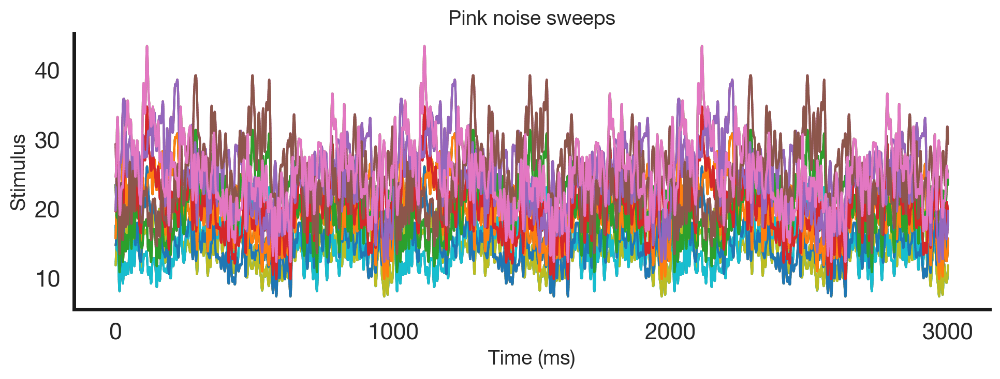

In [4]:
# Process sweeps and extract features
pink_types = process_pink_type_info(f, fs)

In [5]:
_pickle_paths = {
    'stim': os.path.join(PICKLE_DIR, 'df_stim_features.pkl'),
    'data': os.path.join(PICKLE_DIR, 'all_data.pkl'),
}
df_stim_features, all_data_flat = load_or_compute_cell_data(
    _pickle_paths, FORCE_RERUN,
    n_sweeps=66, f=f, one_ms=one_ms, fs=fs, pink_types=pink_types,
)


Loaded df_stim_features and all_data from pickle.


## 3. Spike Waveform Parameterization

We fit every spike with the `Spike` class, extracting: peak amplitude, peak sharpness, peak width, exp_lambda, exp_const, inflection time, and log ISI — the same feature set used across all datasets.

### 3a. Fitting

In [6]:
sp = Spike(thresh_amp= -10, window_length=(5., 5.), smooth_frac=.008, pre_inflection_ms = 0.5)
sp.fit(all_data_flat, fs, n_jobs=-1, progress=tqdm)

Spike:   0%|          | 0/820 [00:09<?, ?it/s]

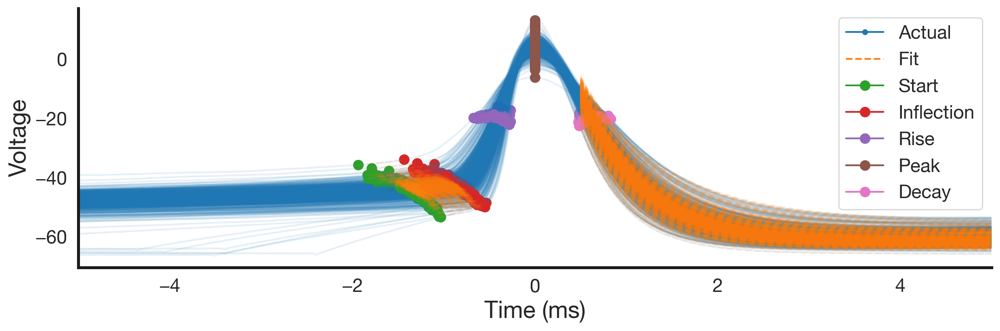

In [7]:
sp.plot(show_points=True)

In [8]:
sp.filter_features()

In [9]:
df_features = sp.df_features

### 3b. Merging with Stimulus Metadata

Concatenate the `Spike` feature DataFrame with the per-spike stimulus table, yielding one row per spike with both waveform parameters and stimulus context.

In [10]:
df = pd.concat([df_stim_features, df_features], axis=1)
df = df.dropna(subset=['stim_type'])

In [11]:
_pkl_all = os.path.join(PICKLE_DIR, 'df_all_c1.pkl')
if FORCE_RERUN or not os.path.exists(_pkl_all):
    with open(_pkl_all, 'wb') as fh:
        pickle.dump(df, fh)
    print('Saved df_all_c1.pkl')

## 4. Pink Noise Spike Analysis

### 4a. Waveform Gallery

Raw spike waveforms from pink noise sweeps only, showing the within-condition variability that the regression models aim to explain.

In [12]:
pink_spikes = df[df['stim_type'] == 'pink']

# Get the indices to plot
indices_to_plot = pink_spikes.index.tolist()

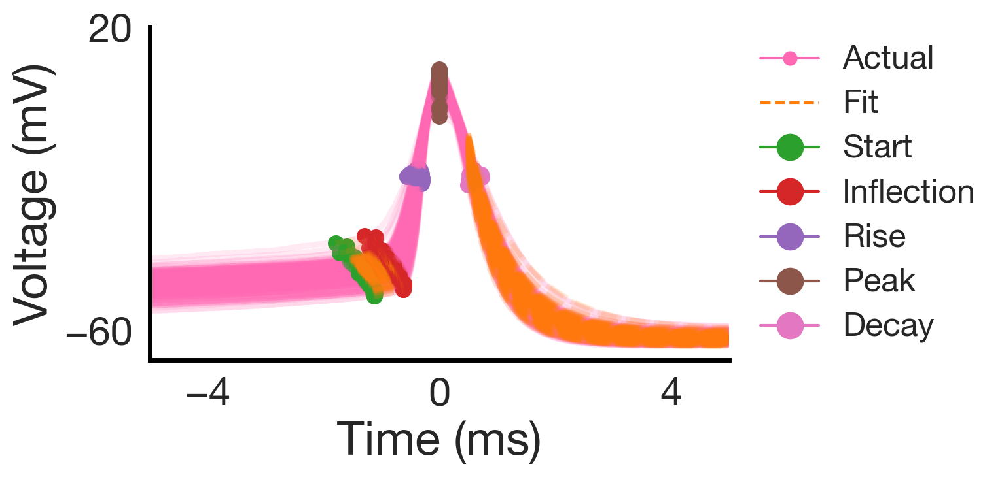

In [13]:
plot_pink_spikes(sp, indices_to_plot)

### 4b. Last-Spike-of-Sweep Filtering

The last spike of each sweep is excluded from all regression analyses — these spikes have inflated ISIs (no successor spike) that skew the log ISI distribution.

In [14]:
last_spikes_indices = df.groupby('sweep').tail(1).index
print("Indices of last spikes in each sweep:", last_spikes_indices)

Indices of last spikes in each sweep: Int64Index([  3,   9,  10,  11,  12,  13,  42,  45,  49,  56,  63,  64,  74,
             87,  98, 104, 132, 158, 185, 193, 194, 198, 204, 211, 212, 221,
            236, 249, 255, 279, 305, 331, 357, 358, 364, 371, 379, 385, 401,
            416, 431, 441, 470, 499, 529, 563, 577, 631, 722, 735, 769, 819],
           dtype='int64')


### 4c. Correlation Scatter Plots — Pink Spikes

In [15]:
df_pink = df.loc[df['stim_type'] == 'pink']
valid_indices = [idx for idx in last_spikes_indices if idx in df_pink.index]
df_pink_filtered = df_pink.drop(valid_indices)


In [16]:
_pkl_pink = os.path.join(PICKLE_DIR, 'df_pink_filtered_c1.pkl')
if FORCE_RERUN or not os.path.exists(_pkl_pink):
    with open(_pkl_pink, 'wb') as fh:
        pickle.dump(df_pink_filtered, fh)
    print('Saved df_pink_filtered_c1.pkl')

  Loading stim features (200ms) from cache...
Pairwise spike x stim correlations (200 ms window), BH-FDR across 24 tests:
stim_target   spike_feature   n         r            p        q_fdr  sig_fdr
   stim_exp  peak_sharpness 391  0.744670 2.681308e-70 3.217570e-69     True
   stim_exp      exp_lambda 391  0.732793 4.998351e-67 3.998681e-66     True
   stim_exp      peak_width 391 -0.718785 2.175233e-63 8.700932e-63     True
   stim_exp inflection_time 391 -0.654630 3.333401e-49 1.000020e-48     True
   stim_exp  inflection_amp 391 -0.653990 4.436764e-49 1.183137e-48     True
   stim_exp       exp_const 391 -0.606548 1.187528e-40 2.375056e-40     True
   stim_exp        peak_amp 391  0.499249 4.886100e-26 6.898024e-26     True
   stim_exp        ramp_amp 391 -0.158082 1.714986e-03 1.789551e-03     True
  stim_mean  peak_sharpness 391 -0.746715 7.028488e-71 1.686837e-69     True
  stim_mean       exp_const 391  0.725273 4.790795e-65 2.874477e-64     True
  stim_mean      exp_lambda 391




In [17]:
window_ms = 200  # change to explore different pre-spike windows (5, 25, 50, 100, 200, 300, 400, 500)

if 'df_pink_raw_filtered' not in vars():
    _df_pink_raw = df.loc[df['stim_type'] == 'pink']
    _valid_raw   = [i for i in last_spikes_indices if i in _df_pink_raw.index]
    df_pink_raw_filtered = _df_pink_raw.drop(_valid_raw)

df_w = prepare_window_df(df_pink_filtered, df_pink_raw_filtered, f, fs, one_ms, window_ms,
                         pickle_dir=PICKLE_DIR)
plot_top_correlations_by_window(df_w, window_ms=window_ms)


## 5. Classification: Decoding Stimulus Type

As a direct test of stimulus-driven variability, we train three classifiers — logistic regression, SVM, and random forest — to predict stimulus type (constant / ramp / pink) from spike waveform features alone.

### 5a. Data Preparation

Drop NaNs, build feature matrix X (waveform features only) and target y (stimulus type), then split into 80/20 train/test.

In [18]:
df = df.dropna(subset=['stim_type'])

X = df.drop(columns=['stim_type', 'spike_num', 'sweep', 'stim_exp','stim_mean','stim_std', 'pink_type',
                      'log_isi', 'log_isi_prev', 'n_spikes_50ms', 'n_spikes_200ms'],
            inplace=False)  # waveform features only - same rationale as excluding log_isi
y = df['stim_type']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

### 5b. Logistic Regression — Linear Stimulus-Type Decoder

In [19]:
pickle_path_model = os.path.join(PICKLE_DIR, 'logr_model.pkl')
pickle_path_accs  = os.path.join(PICKLE_DIR, 'logr_accs.pkl')
if not FORCE_RERUN and os.path.exists(pickle_path_model):
    with open(pickle_path_model, 'rb') as file:
        logr_model = pickle.load(file)
    with open(pickle_path_accs, 'rb') as file:
        logr_accs = pickle.load(file)
    print('Loaded logr_model and logr_accs from pickle.')
else:
    logr_model, logr_accs = logistic_regression_stim(X, y, X_train, X_test, y_train, y_test)
    with open(pickle_path_model, 'wb') as file:
        pickle.dump(logr_model, file)
    with open(pickle_path_accs, 'wb') as file:
        pickle.dump(logr_accs, file)
    print('Trained and saved logr_model.')
logr_acc = logr_model.score(X_test, y_test)


Loaded logr_model and logr_accs from pickle.


### 5c. SVM — Nonlinear Stimulus-Type Decoder

In [20]:
pickle_path_model = os.path.join(PICKLE_DIR, 'svm_model.pkl')
pickle_path_accs  = os.path.join(PICKLE_DIR, 'svm_accs.pkl')
if not FORCE_RERUN and os.path.exists(pickle_path_model):
    with open(pickle_path_model, 'rb') as file:
        svm_model = pickle.load(file)
    with open(pickle_path_accs, 'rb') as file:
        svm_accs = pickle.load(file)
    print('Loaded svm_model and svm_accs from pickle.')
else:
    svm_model, svm_accs = svm_stim(X, y, X_train, X_test, y_train, y_test)
    with open(pickle_path_model, 'wb') as file:
        pickle.dump(svm_model, file)
    with open(pickle_path_accs, 'wb') as file:
        pickle.dump(svm_accs, file)
    print('Trained and saved svm_model.')
svm_acc = svm_model.score(X_test, y_test)


Loaded svm_model and svm_accs from pickle.


### 5d. Random Forest — Ensemble Decoder + Feature Importance

In [21]:
_mask = pd.notna(y_train) & pd.notna(y_test)
y_train_clean = y_train[pd.notna(y_train)]
X_train_clean = X_train.loc[y_train_clean.index]
y_test_clean  = y_test[pd.notna(y_test)]
X_test_clean  = X_test.loc[y_test_clean.index]

pickle_path_model       = os.path.join(PICKLE_DIR, 'rf_model.pkl')
pickle_path_accs        = os.path.join(PICKLE_DIR, 'rf_accs.pkl')
pickle_path_importances = os.path.join(PICKLE_DIR, 'rf_importances.pkl')

_needs_train = True
if not FORCE_RERUN and os.path.exists(pickle_path_model) and os.path.exists(pickle_path_importances):
    try:
        with open(pickle_path_model, 'rb') as file:
            rf_model = pickle.load(file)
        with open(pickle_path_accs, 'rb') as file:
            rf_accs = pickle.load(file)
        with open(pickle_path_importances, 'rb') as file:
            rf_importances = pickle.load(file)
        print('Loaded rf_model, rf_accs, and rf_importances from pickle.')
        _needs_train = False
    except Exception as _e:
        print(f'Pickle load failed ({_e}); retraining.')

if _needs_train:
    rf_model, rf_accs, rf_importances = random_forest_stim(X_train_clean, y_train_clean, X_train_clean, X_test_clean, y_train_clean, y_test_clean)
    with open(pickle_path_model, 'wb') as file:
        pickle.dump(rf_model, file)
    with open(pickle_path_accs, 'wb') as file:
        pickle.dump(rf_accs, file)
    with open(pickle_path_importances, 'wb') as file:
        pickle.dump(rf_importances, file)
    print('Trained and saved rf_model, rf_accs, and rf_importances to pickle.')

Loaded rf_model, rf_accs, and rf_importances from pickle.


In [22]:
# Calculate average accuracy
rf_avg_accs = np.mean(rf_accs)

rf_stdev_accs = np.std(rf_accs)

### 5e. Model Comparison

Bootstrap-estimated accuracy distributions for logistic regression, SVM, and random forest side-by-side (train/test split, for comparing model types). The random forest confusion matrix and feature importances used for the main figure below use out-of-fold 5-fold CV instead - every one of the 820 spikes gets a genuinely held-out prediction, rather than only the 164-spike test split.

In [23]:
print(f"Accuracy Logistic Regression: {logr_acc: .3f}")
print(f"Accuracy SVM: {svm_acc: .3f}")
print(f"Mean Accuracy Random Forest: {rf_avg_accs: .3f}")
print(f"Stdev Accuracy Random Forest: {rf_stdev_accs: .3f}")

Accuracy Logistic Regression:  0.622
Accuracy SVM:  0.695
Mean Accuracy Random Forest:  0.734
Stdev Accuracy Random Forest:  0.017


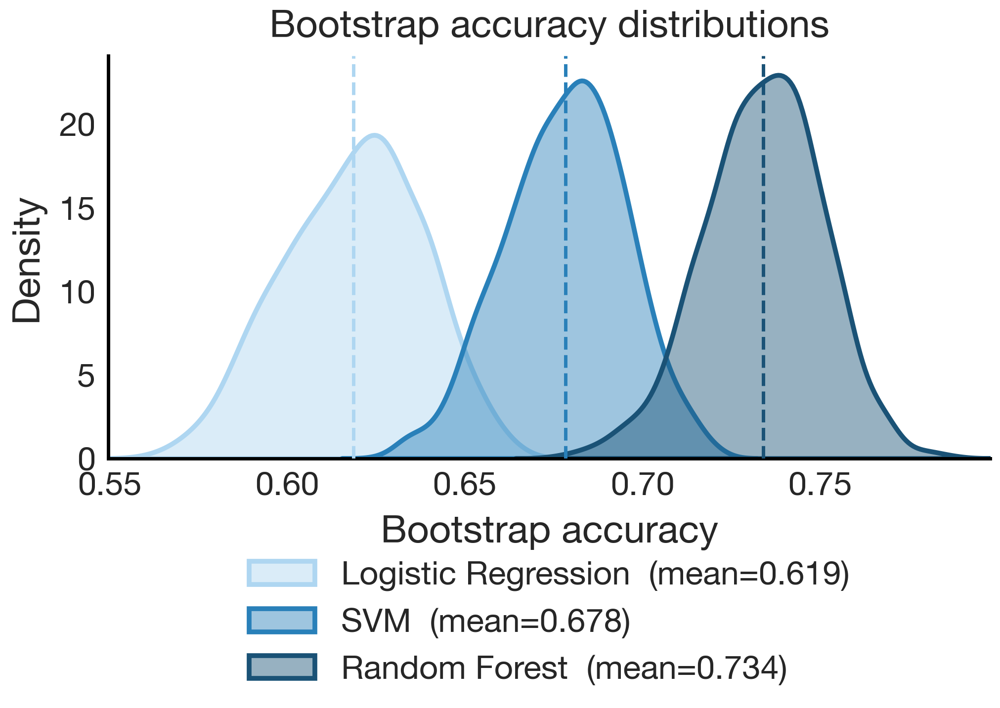

In [24]:
plot_bootstrap_histograms([logr_accs, svm_accs, rf_accs], ["Logistic Regression", "SVM", "Random Forest"], overlay=True)

In [25]:
# ── Out-of-fold predictions + per-fold feature importances ────────────────────
# A single 80/20 train/test split only evaluates 164/820 spikes and only ever trains
# feature-importance estimates on the 656-spike training fold. Out-of-fold 5-fold CV
# (same hyperparameters the grid search already found) uses every one of the 820
# spikes for both the confusion matrix and the feature importances below.
from sklearn.model_selection import cross_val_predict, cross_validate, StratifiedKFold
from sklearn.ensemble import RandomForestClassifier

best_params = {k: v for k, v in rf_model.get_params().items() if k not in ('class_weight',)}
cv5 = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
rf_oof = RandomForestClassifier(**best_params, class_weight=None)

y_pred_oof_main = cross_val_predict(rf_oof, X, y, cv=cv5)
_cv_result = cross_validate(rf_oof, X, y, cv=cv5, return_estimator=True)
importances_oof = np.array([est.feature_importances_ for est in _cv_result['estimator']])

print(f'Out-of-fold accuracy (all {len(y)} spikes): {np.mean(y == y_pred_oof_main):.3f}')

Out-of-fold accuracy (all 820 spikes): 0.779


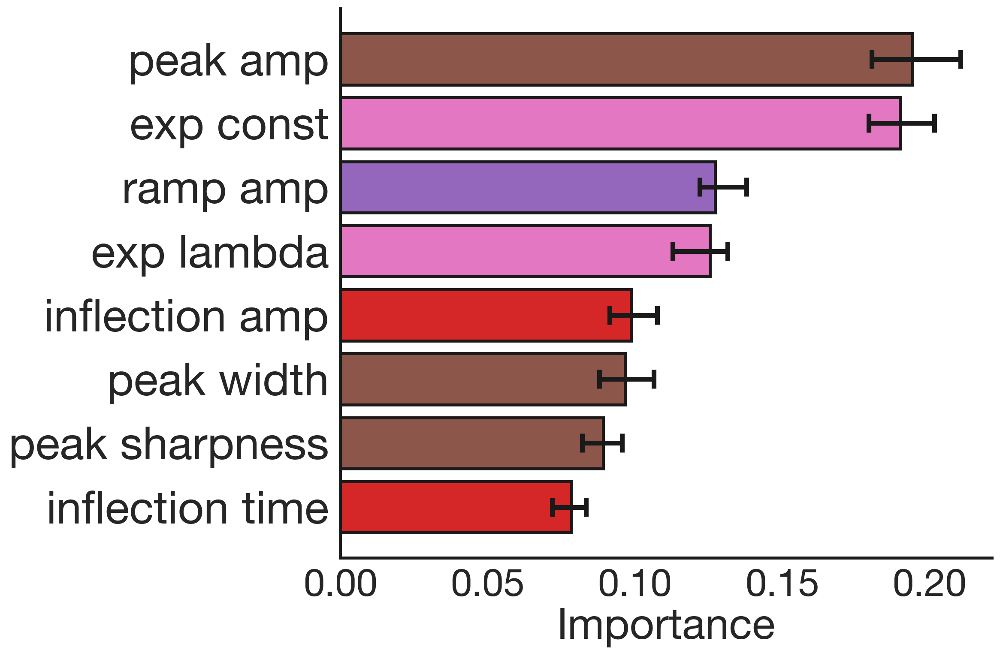

In [26]:
plot_feature_importance_categorical(rf_model, X, importances_oof)

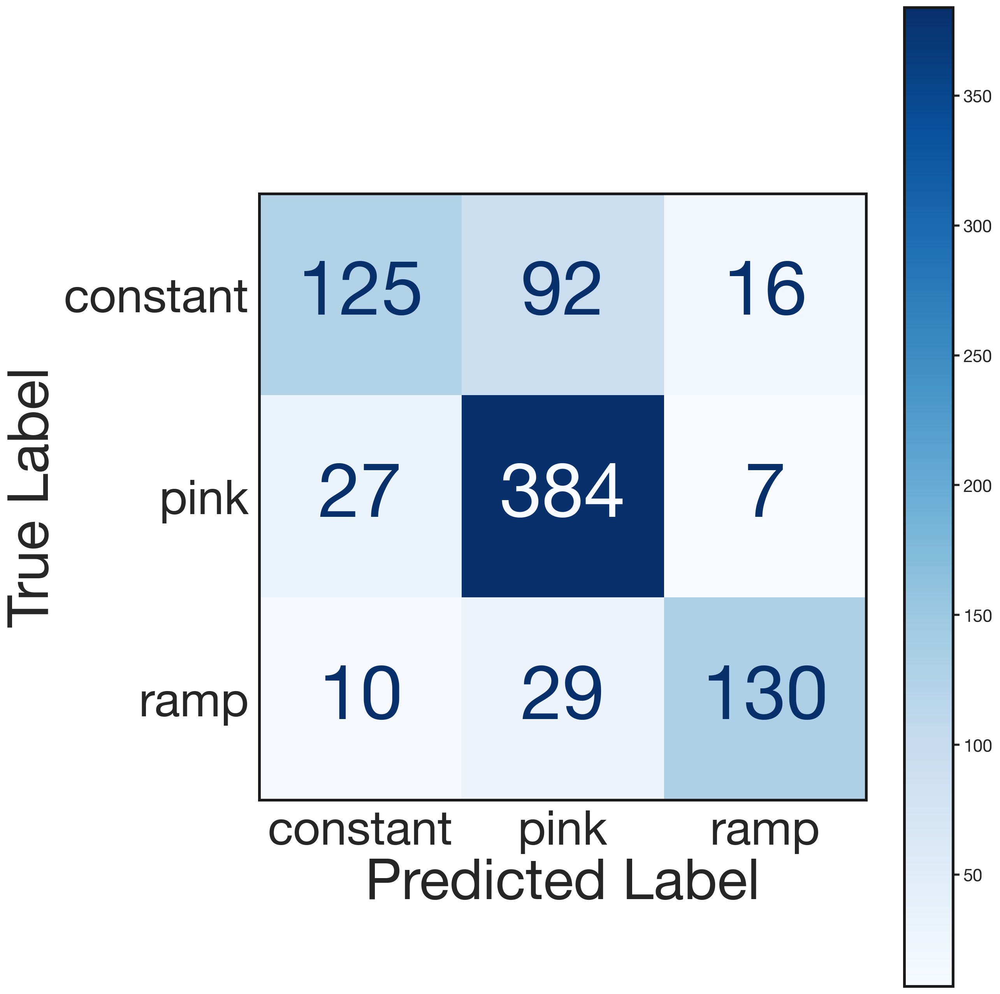

In [27]:
plot_confusion_matrix(rf_model, X, y, y_pred=y_pred_oof_main)

## 6. Regression: Predicting Stimulus Statistics

Using ridge regression (k-fold CV), we predict instantaneous pink noise stimulus properties (exponent, mean, std) from spike waveform features. R² tells us how much variance in the stimulus is captured by waveform shape alone.

### 6a. Ridge Regression

In [28]:
pickle_path = os.path.join(PICKLE_DIR, 'ridge_results_stim_stats.pkl')
if not FORCE_RERUN and os.path.exists(pickle_path):
    with open(pickle_path, 'rb') as file:
        ridge_results_dict = pickle.load(file)
    print('Loaded ridge_results_dict from pickle.')
else:
    ridge_results_dict = {}
    for stim_feature in ['stim_exp', 'stim_mean', 'stim_std']:
        print(f"\n--- Processing {stim_feature} ---\n")
        data = df_pink_filtered.dropna(subset=[stim_feature])
        X = data.drop(columns=['stim_exp', 'stim_mean', 'stim_std'])
        y = data[stim_feature]
        ridge_results = run_ridge_regression_kfold(X, y)
        ridge_results_dict[stim_feature] = ridge_results
        print(f"Mean R² for {stim_feature}: {ridge_results['r2_mean']:.3f}")
        print(f"95% CI for R²: {ridge_results['r2_ci']}")
    with open(pickle_path, 'wb') as file:
        pickle.dump(ridge_results_dict, file)
    print('Saved ridge_results_dict to pickle.')

Loaded ridge_results_dict from pickle.


### 6b. Results

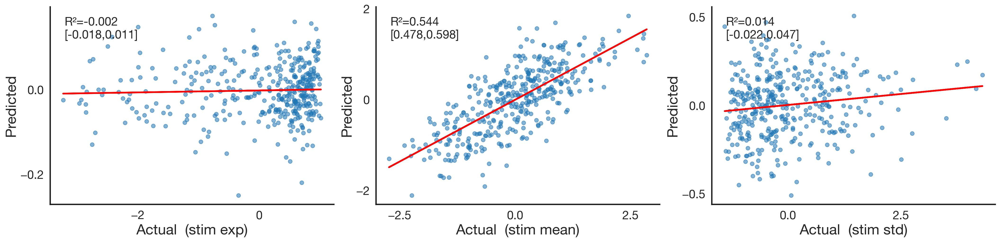

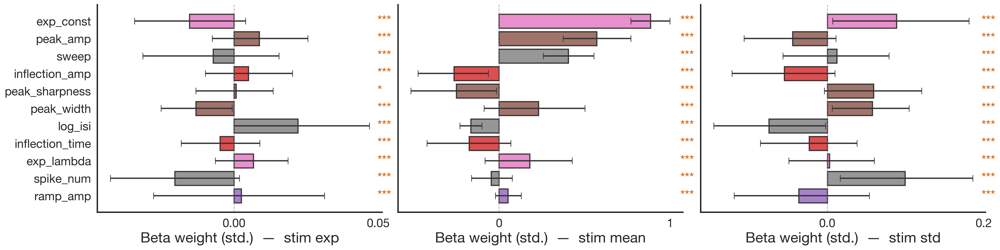

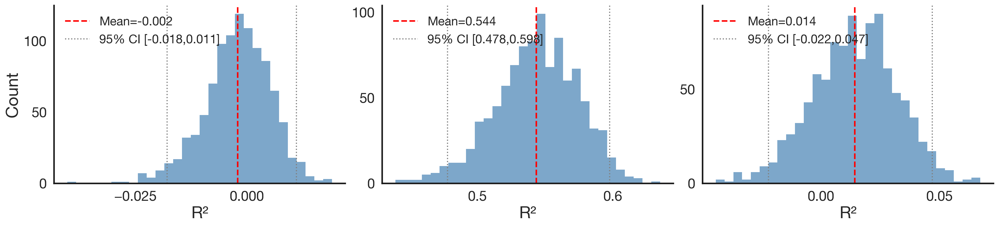

FDR (BH, q=0.05): 2/3 raw p<0.05 → 2/3 after correction
  stim_exp         R²=-0.002  p_perm=0.051  p_fdr=0.051  
  stim_mean        R²=0.544  p_perm=0.001  p_fdr=0.003 *
  stim_std         R²=0.014  p_perm=0.003  p_fdr=0.004 *


{'stim_exp': {'y_true': array([ 9.73819733e-01,  4.09446596e-01,  8.13191083e-01,  9.73846289e-01,
          9.10364735e-01, -9.90286578e-01, -1.99360157e+00, -9.93310459e-02,
          7.09948226e-01, -5.46261205e-01,  5.83884419e-01,  7.17045098e-01,
          7.88040145e-01,  8.37518557e-01, -1.70425182e+00,  5.88312114e-01,
          9.62738323e-01, -7.29480653e-01,  8.18020981e-01,  9.62229884e-01,
          1.28500683e-02,  3.65971177e-01, -2.84190555e-01,  8.27072593e-01,
         -7.70726372e-01, -1.75970807e+00,  2.72599183e-01,  5.49978793e-01,
         -3.97349307e-01,  8.95927128e-01,  2.28502639e-01,  7.20197241e-01,
          5.84868033e-01, -1.96320959e+00,  4.33293455e-01,  8.24745652e-01,
          9.36303734e-01,  3.58186514e-01,  8.00094519e-01,  9.78614663e-01,
          1.00197727e+00,  6.91141055e-01, -9.45363179e-01,  5.59968879e-01,
          7.01024180e-01,  8.49138706e-01, -3.34923492e-01,  8.97872837e-01,
          8.44111572e-01, -4.99486720e-01,  7.87100447

In [29]:
_targets = ['stim_exp', 'stim_mean', 'stim_std']
_ys = {t: df_pink_filtered.dropna(subset=[t])[t] for t in _targets}
plot_ridge_results_grid(
    ridge_results_dict, keys=_targets,
    labels=['stim exp', 'stim mean', 'stim std'], ys=_ys,
)
apply_fdr_pvc6(ridge_results_dict)


**NOTE:** The R² values above use the **5 ms default pre-spike window** (`ridge_results_stim_stats.pkl`). These are NOT the paper-reported values. The paper reports results from the **200 ms window** computed in Section 7 below. See the "Paper-reported values" cell at the end of Section 7.

## 7. Pre-Spike Stimulus Window Analysis

### 7a. Window Expansion

Compare ridge regression R² across pre-inflection window sizes {5, 25, 50, 100, 200, 300, 400, 500} ms. Paired shuffle controls (Y permuted per window) establish the null R² at each window size.

Loaded results_window (48 entries).
All windows (including shuffle controls) already computed.
Saved updated results_window to pickle.


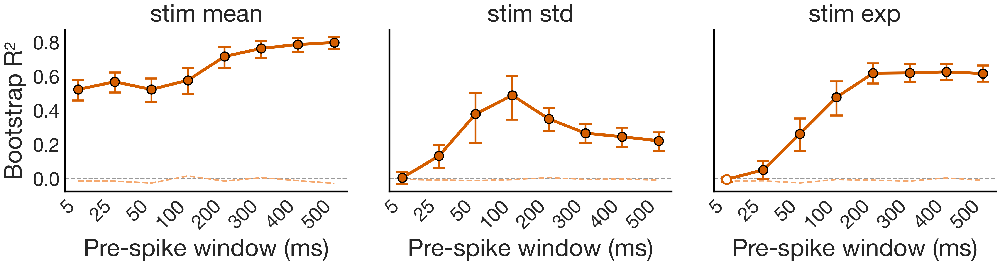

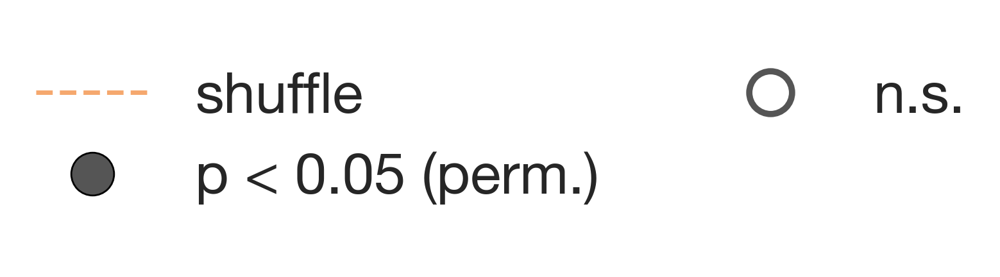

In [30]:
if 'df_pink_raw_filtered' not in vars():
    df_pink_raw = df.loc[df['stim_type'] == 'pink']
    valid_idx_raw = [i for i in last_spikes_indices if i in df_pink_raw.index]
    df_pink_raw_filtered = df_pink_raw.drop(valid_idx_raw)

WINDOWS_MS  = [5, 25, 50, 100, 200, 300, 400, 500]
pickle_path = os.path.join(PICKLE_DIR, 'results_window.pkl')

results_window = {}
if not FORCE_RERUN and os.path.exists(pickle_path):
    try:
        with open(pickle_path, 'rb') as file:
            results_window = pickle.load(file)
        print(f'Loaded results_window ({len(results_window)} entries).')
    except Exception as _e:
        print(f'Pickle load failed ({_e}); recomputing.')

results_window = run_window_expansion(
    WINDOWS_MS, df_pink_filtered, df_pink_raw_filtered,
    f, fs, one_ms, existing=results_window,
)

with open(pickle_path, 'wb') as file:
    pickle.dump(results_window, file)
print('Saved updated results_window to pickle.')

_shuf_results = {f'{w}ms_{t}': results_window[f'shuf_{w}ms_{t}']
                 for w in WINDOWS_MS for t in ['stim_mean', 'stim_std', 'stim_exp']
                 if f'shuf_{w}ms_{t}' in results_window} or None

plot_window_expansion(
    results_window, WINDOWS_MS,
    targets=('stim_mean', 'stim_std', 'stim_exp'),
    target_labels=('stim mean', 'stim std', 'stim exp'),
    shuffle_results=_shuf_results,
)


### 7b. Beta Weights — Selected Windows

  Computing stim features (25ms) — pass pickle_dir to cache...


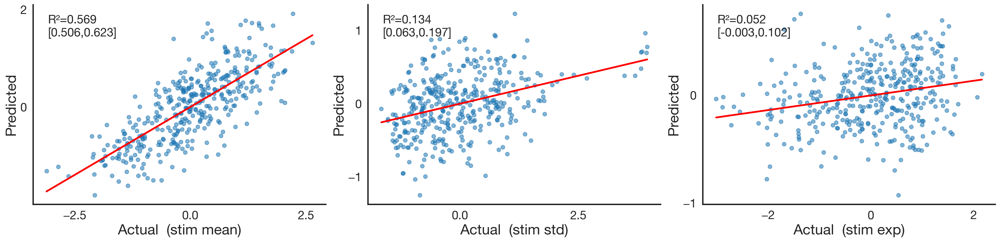

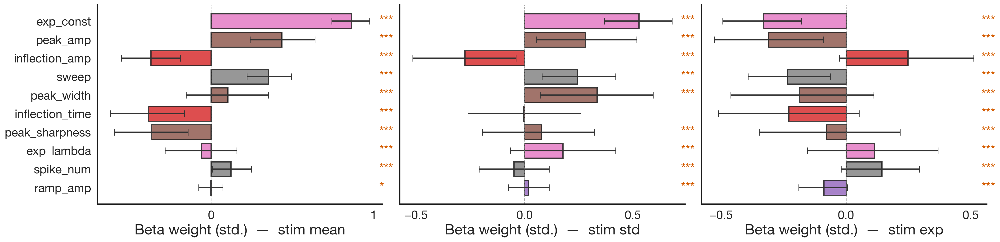

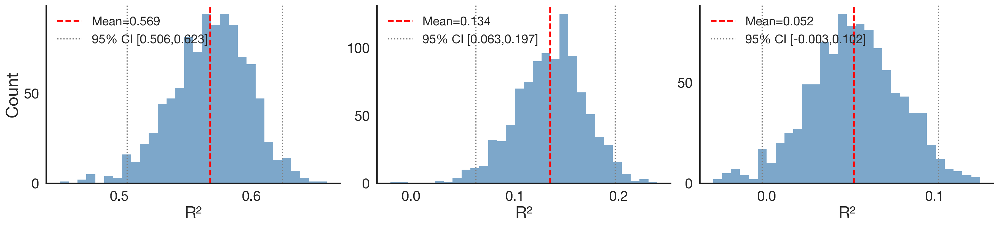

  Computing stim features (50ms) — pass pickle_dir to cache...


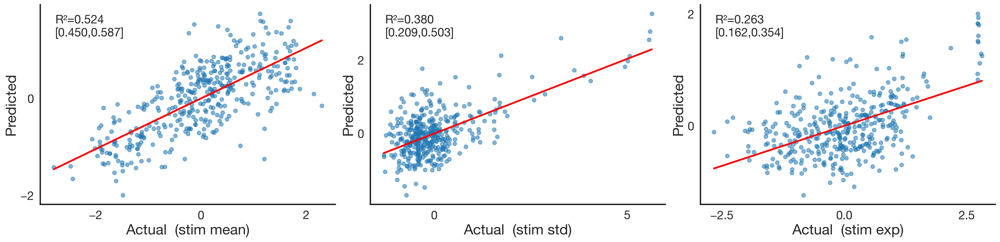

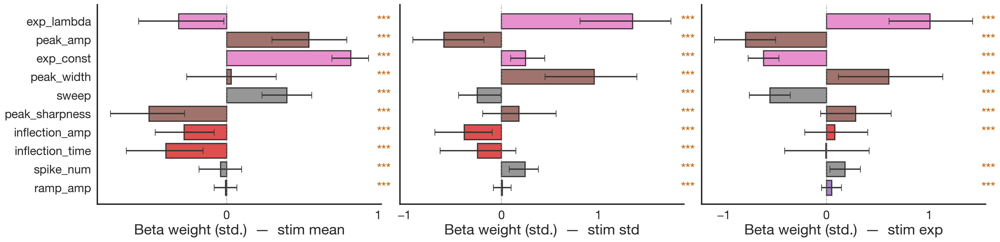

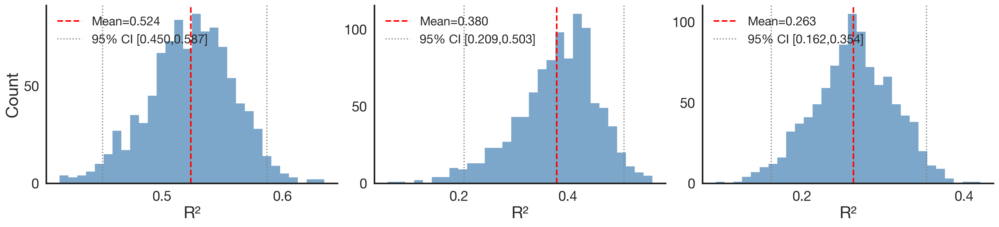

  Computing stim features (100ms) — pass pickle_dir to cache...


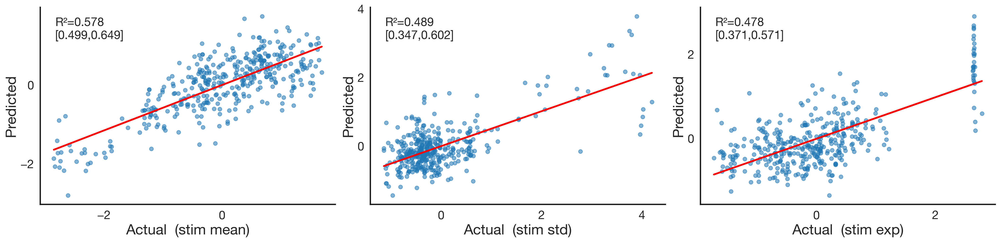

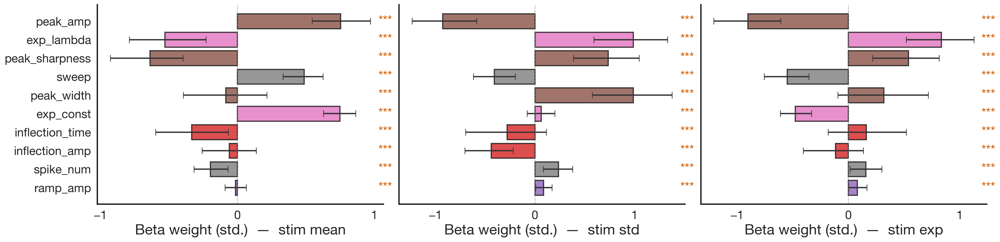

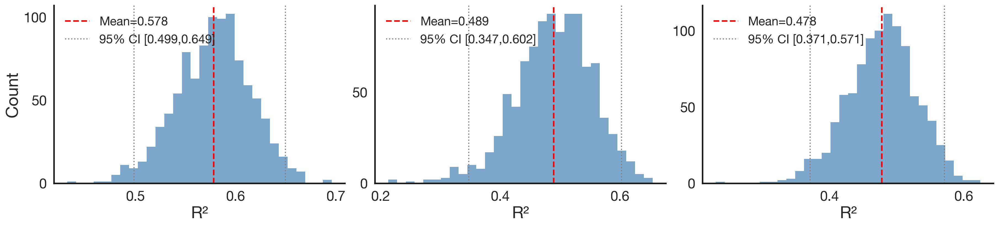

In [31]:
_targets = ['stim_mean', 'stim_std', 'stim_exp']
for wms in [25, 50, 100]:
    df_w  = prepare_window_df(df_pink_filtered, df_pink_raw_filtered, f, fs, one_ms, wms)
    _keys = [f'{wms}ms_{t}' for t in _targets]
    _ys   = {f'{wms}ms_{t}': df_w.dropna(subset=[t])[t] for t in _targets}
    plot_ridge_results_grid(
        results_window, keys=_keys,
        labels=['stim mean', 'stim std', 'stim exp'], ys=_ys,
    )


### 7c. Top Spike–Stim Correlations by Window

Pairwise spike x stim correlations (5 ms window), BH-FDR across 24 tests:
stim_target   spike_feature   n         r            p        q_fdr  sig_fdr
   stim_exp       exp_const 391 -0.092378 6.804480e-02 2.332965e-01    False
   stim_exp      peak_width 391 -0.087920 8.251031e-02 2.475309e-01    False
   stim_exp        peak_amp 391  0.067971 1.798241e-01 3.465253e-01    False
   stim_exp      exp_lambda 391  0.066764 1.877012e-01 3.465253e-01    False
   stim_exp inflection_time 391 -0.060156 2.353159e-01 3.608790e-01    False
   stim_exp  peak_sharpness 391  0.052118 3.039637e-01 4.291253e-01    False
   stim_exp  inflection_amp 391 -0.031035 5.406356e-01 6.178693e-01    False
   stim_exp        ramp_amp 391 -0.005972 9.062941e-01 9.456982e-01    False
  stim_mean       exp_const 391  0.477663 1.116080e-23 2.678591e-22     True
  stim_mean        ramp_amp 391  0.202111 5.690237e-05 6.828285e-04     True
  stim_mean      peak_width 391  0.157434 1.792731e-03 1.144176e-02     True
  

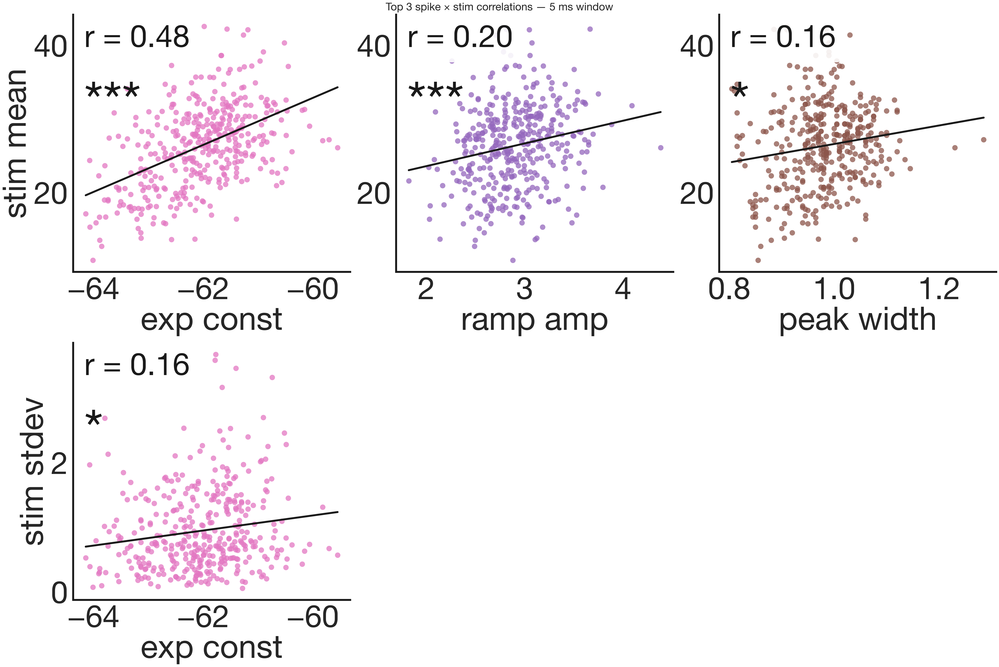

  Loading stim features (25ms) from cache...
Pairwise spike x stim correlations (25 ms window), BH-FDR across 24 tests:
stim_target   spike_feature   n         r            p        q_fdr  sig_fdr
   stim_exp       exp_const 391 -0.234001 2.906045e-06 1.743627e-05     True
   stim_exp      peak_width 391 -0.166093 9.783474e-04 2.935042e-03     True
   stim_exp  peak_sharpness 391  0.135758 7.181557e-03 1.723574e-02     True
   stim_exp inflection_time 391 -0.133602 8.163771e-03 1.781186e-02     True
   stim_exp      exp_lambda 391  0.130557 9.754854e-03 1.950971e-02     True
   stim_exp        ramp_amp 391 -0.120881 1.678438e-02 2.877322e-02     True
   stim_exp        peak_amp 391  0.106350 3.553817e-02 5.686107e-02    False
   stim_exp  inflection_amp 391 -0.091649 7.025827e-02 9.918814e-02    False
  stim_mean       exp_const 391  0.551360 1.780181e-32 4.272435e-31     True
  stim_mean      peak_width 391  0.283986 1.093323e-08 1.311988e-07     True
  stim_mean  peak_sharpness 391 -

  Loading stim features (50ms) from cache...
Pairwise spike x stim correlations (50 ms window), BH-FDR across 24 tests:
stim_target   spike_feature   n         r            p        q_fdr  sig_fdr
   stim_exp       exp_const 391 -0.413426 1.419054e-17 6.811461e-17     True
   stim_exp  peak_sharpness 391  0.390985 9.884616e-16 3.389011e-15     True
   stim_exp      exp_lambda 391  0.385167 2.820237e-15 8.460711e-15     True
   stim_exp      peak_width 391 -0.357914 2.925243e-13 6.382347e-13     True
   stim_exp  inflection_amp 391 -0.312422 2.670849e-10 4.930798e-10     True
   stim_exp inflection_time 391 -0.294492 2.907816e-09 4.652505e-09     True
   stim_exp        peak_amp 391  0.248540 6.453314e-07 8.151555e-07     True
   stim_exp        ramp_amp 391 -0.092318 6.822365e-02 7.442580e-02    False
  stim_mean       exp_const 391  0.614868 5.009626e-42 1.202310e-40     True
  stim_mean      peak_width 391  0.427169 8.971952e-19 1.076634e-17     True
  stim_mean  peak_sharpness 391 -

  Loading stim features (100ms) from cache...
Pairwise spike x stim correlations (100 ms window), BH-FDR across 24 tests:
stim_target   spike_feature   n         r            p        q_fdr  sig_fdr
   stim_exp  peak_sharpness 391  0.600269 1.218419e-39 1.462103e-38     True
   stim_exp      exp_lambda 391  0.585136 2.709342e-37 1.625605e-36     True
   stim_exp      peak_width 391 -0.555310 5.191207e-33 1.779842e-32     True
   stim_exp       exp_const 391 -0.529798 1.123207e-29 3.369621e-29     True
   stim_exp  inflection_amp 391 -0.514422 8.468119e-28 1.693624e-27     True
   stim_exp inflection_time 391 -0.487479 9.905061e-25 1.828627e-24     True
   stim_exp        peak_amp 391  0.377825 1.028560e-14 1.299234e-14     True
   stim_exp        ramp_amp 391 -0.086202 8.870878e-02 9.256569e-02    False
  stim_mean       exp_const 391  0.661908 1.229503e-50 2.950807e-49     True
  stim_mean  peak_sharpness 391 -0.594036 1.168305e-38 9.346441e-38     True
  stim_mean      peak_width 391

  Loading stim features (200ms) from cache...
Pairwise spike x stim correlations (200 ms window), BH-FDR across 24 tests:
stim_target   spike_feature   n         r            p        q_fdr  sig_fdr
   stim_exp  peak_sharpness 391  0.744670 2.681308e-70 3.217570e-69     True
   stim_exp      exp_lambda 391  0.732793 4.998351e-67 3.998681e-66     True
   stim_exp      peak_width 391 -0.718785 2.175233e-63 8.700932e-63     True
   stim_exp inflection_time 391 -0.654630 3.333401e-49 1.000020e-48     True
   stim_exp  inflection_amp 391 -0.653990 4.436764e-49 1.183137e-48     True
   stim_exp       exp_const 391 -0.606548 1.187528e-40 2.375056e-40     True
   stim_exp        peak_amp 391  0.499249 4.886100e-26 6.898024e-26     True
   stim_exp        ramp_amp 391 -0.158082 1.714986e-03 1.789551e-03     True
  stim_mean  peak_sharpness 391 -0.746715 7.028488e-71 1.686837e-69     True
  stim_mean       exp_const 391  0.725273 4.790795e-65 2.874477e-64     True
  stim_mean      exp_lambda 391

  Loading stim features (300ms) from cache...
Pairwise spike x stim correlations (300 ms window), BH-FDR across 24 tests:
stim_target   spike_feature   n         r            p        q_fdr  sig_fdr
   stim_exp  peak_sharpness 391  0.740592 3.727676e-69 1.789285e-68     True
   stim_exp      peak_width 391 -0.737893 2.072030e-68 8.288120e-68     True
   stim_exp      exp_lambda 391  0.732098 7.672599e-67 2.630605e-66     True
   stim_exp inflection_time 391 -0.672662 7.894369e-53 1.894649e-52     True
   stim_exp  inflection_amp 391 -0.655243 2.533280e-49 5.527157e-49     True
   stim_exp       exp_const 391 -0.623483 1.707172e-43 3.414344e-43     True
   stim_exp        peak_amp 391  0.498891 5.363346e-26 9.194307e-26     True
   stim_exp        ramp_amp 391 -0.129949 1.010361e-02 1.054290e-02     True
  stim_mean  peak_sharpness 391 -0.796611 4.633290e-87 1.111990e-85     True
  stim_mean      exp_lambda 391 -0.777300 2.663364e-80 3.196037e-79     True
  stim_mean      peak_width 391

  Loading stim features (400ms) from cache...
Pairwise spike x stim correlations (400 ms window), BH-FDR across 24 tests:
stim_target   spike_feature   n         r            p        q_fdr  sig_fdr
   stim_exp      peak_width 391 -0.733245 3.782405e-67 1.815554e-66     True
   stim_exp  peak_sharpness 391  0.720453 8.244287e-64 2.473286e-63     True
   stim_exp      exp_lambda 391  0.716726 7.144255e-63 1.905135e-62     True
   stim_exp inflection_time 391 -0.664143 4.382500e-51 1.051800e-50     True
   stim_exp  inflection_amp 391 -0.639280 2.623983e-46 5.725055e-46     True
   stim_exp       exp_const 391 -0.610634 2.538319e-41 5.076638e-41     True
   stim_exp        peak_amp 391  0.484621 2.021305e-24 3.465095e-24     True
   stim_exp        ramp_amp 391 -0.129365 1.044896e-02 1.090327e-02     True
  stim_mean  peak_sharpness 391 -0.819912 2.910709e-96 6.985701e-95     True
  stim_mean      peak_width 391  0.807858 2.409482e-91 2.891379e-90     True
  stim_mean      exp_lambda 391

  Loading stim features (500ms) from cache...
Pairwise spike x stim correlations (500 ms window), BH-FDR across 24 tests:
stim_target   spike_feature   n         r            p        q_fdr  sig_fdr
   stim_exp      peak_width 391 -0.714521 2.521345e-62 8.644612e-62     True
   stim_exp  peak_sharpness 391  0.689463 1.905728e-56 5.717185e-56     True
   stim_exp      exp_lambda 391  0.688944 2.485868e-56 6.628982e-56     True
   stim_exp inflection_time 391 -0.641986 8.325790e-47 1.998190e-46     True
   stim_exp  inflection_amp 391 -0.598654 2.199034e-39 4.797893e-39     True
   stim_exp       exp_const 391 -0.593009 1.687444e-38 3.374888e-38     True
   stim_exp        peak_amp 391  0.452624 3.820545e-21 6.549506e-21     True
   stim_exp        ramp_amp 391 -0.117576 2.004256e-02 2.091397e-02     True
  stim_mean  peak_sharpness 391 -0.825522 1.116765e-98 2.574934e-97     True
  stim_mean      peak_width 391  0.824873 2.145778e-98 2.574934e-97     True
  stim_mean      exp_lambda 391

In [32]:
for wms in WINDOWS_MS:
    df_w = prepare_window_df(df_pink_filtered, df_pink_raw_filtered, f, fs, one_ms, wms,
                             pickle_dir=PICKLE_DIR)
    plot_top_correlations_by_window(df_w, window_ms=wms, top=True)


### Paper-reported values (200 ms window)

Beta weights with 95% bootstrap CI (24 tested; significant = CI excludes zero):
      tgt            feat   coef  ci_lo  ci_hi  sig_ci
 stim_exp  peak_sharpness  0.599  0.384  0.814    True
 stim_exp        peak_amp -0.565 -0.790 -0.342    True
 stim_exp      exp_lambda  0.553  0.300  0.781    True
 stim_exp       exp_const -0.176 -0.306 -0.045    True
 stim_exp      peak_width  0.084 -0.226  0.358   False
 stim_exp        ramp_amp -0.050 -0.117  0.024   False
 stim_exp  inflection_amp  0.040 -0.153  0.230   False
 stim_exp inflection_time  0.023 -0.215  0.273   False
stim_mean        peak_amp  0.777  0.584  0.984    True
stim_mean      exp_lambda -0.691 -0.906 -0.450    True
stim_mean  peak_sharpness -0.647 -0.882 -0.444    True
stim_mean       exp_const  0.628  0.516  0.735    True
stim_mean inflection_time -0.196 -0.443  0.040   False
stim_mean      peak_width -0.191 -0.482  0.114   False
stim_mean  inflection_amp  0.003 -0.168  0.181   False
stim_mean        ramp_amp -0.001 -0.070 

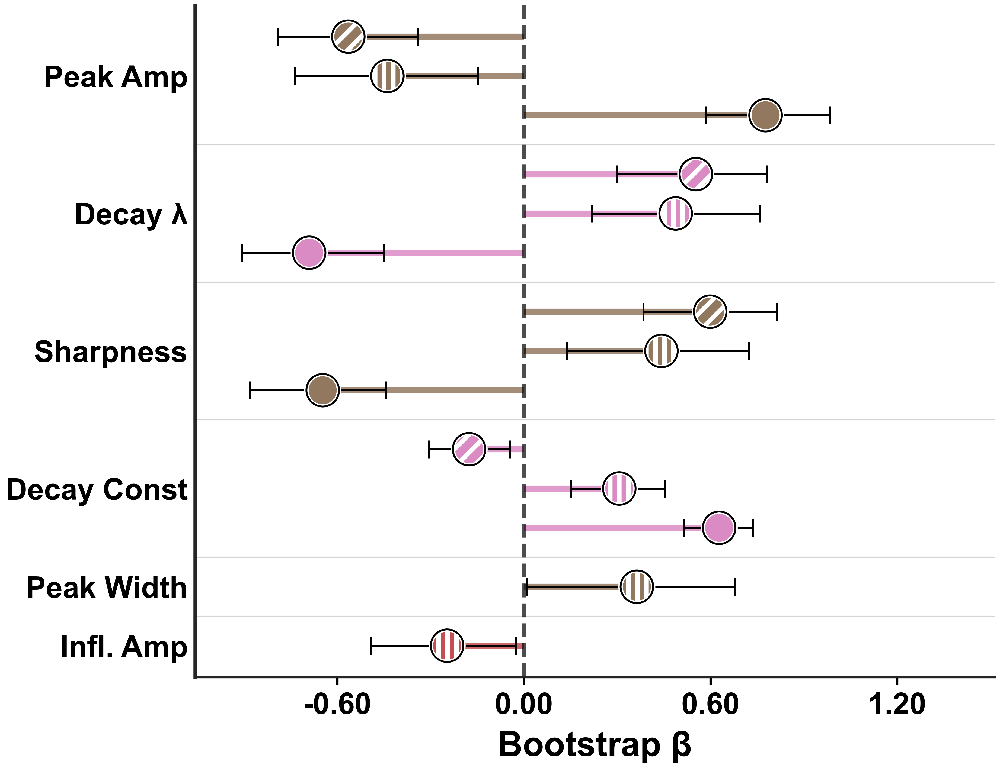

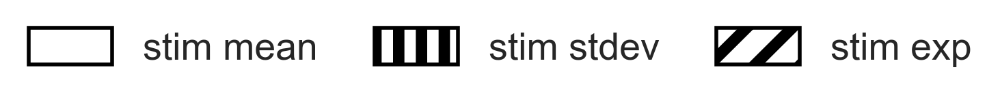

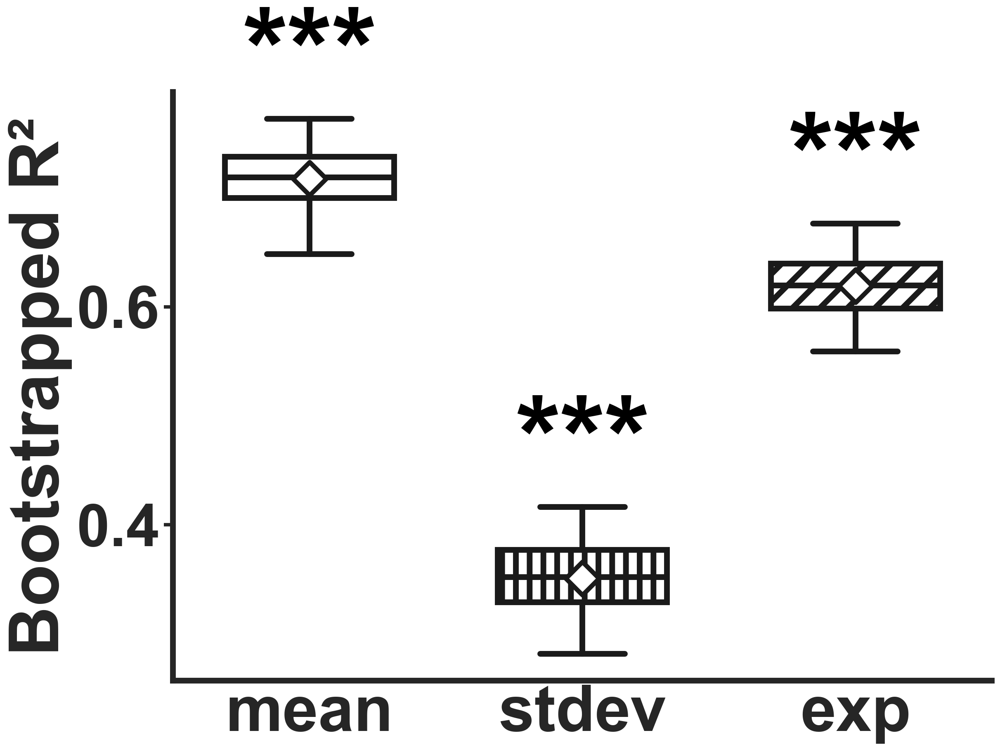

In [4]:
plot_beta_weights_combined(results_window, window_ms=200)

In [34]:
print("=" * 55)
print("PAPER-REPORTED VALUES -- 200 ms pre-spike window")
print("=" * 55)
for _t, _label in [('stim_mean', 'Mean amplitude'),
                   ('stim_std',  'Amplitude variance'),
                   ('stim_exp',  'Spectral exponent')]:
    _res = results_window[f'200ms_{_t}']
    _r2  = _res['r2_mean']
    _ci  = _res['r2_ci']
    _p   = _res['p_val_perm']
    print(f"  {_label:<22}  R2 = {_r2:.3f}  "
          f"95% CI [{_ci[0]:.3f}, {_ci[1]:.3f}]  p = {_p:.3f}")
print("=" * 55)

PAPER-REPORTED VALUES -- 200 ms pre-spike window
  Mean amplitude          R2 = 0.717  95% CI [0.648, 0.772]  p = 0.001
  Amplitude variance      R2 = 0.351  95% CI [0.282, 0.416]  p = 0.001
  Spectral exponent       R2 = 0.619  95% CI [0.559, 0.676]  p = 0.001


---
## Confusion matrix sample size + constant→pink misclassification

Two issues were checked about the confusion matrix originally used for the main figure (`plot_confusion_matrix(rf_model, X_test, y_test)` - only the 20% held-out `train_test_split` test set, not all spikes; 820 total spikes were fit (233 constant + 169 ramp + 418 pink, matching Supp Fig 4a) but the matrix only reflected 164 of them). The "5-fold cross-validation" in the original caption referred to `GridSearchCV(..., cv=5)` for hyperparameter selection on the training set only - it was never used to generate the predictions actually shown. **The main figure above has been updated to use out-of-fold predictions for all 820 spikes** (see the cell above the feature-importance plot).

2. **Constant→pink bias.** Pink is the majority class (418/820 = 51% of spikes, vs. 28% constant, 21% ramp) and `RandomForestClassifier` was trained with no `class_weight` setting - a plausible, checkable explanation for a majority-class bias under uncertainty, separate from any claim about constant/pink waveforms looking biologically similar.

Below: (a) reusing the out-of-fold predictions from the main figure; (b) the same out-of-fold procedure repeated with `class_weight='balanced'`, same hyperparameters otherwise, to isolate whether class weighting changes the constant-spike misclassification pattern.

In [35]:
from sklearn.metrics import confusion_matrix, classification_report
from sklearn.ensemble import RandomForestClassifier

print(f'Total spikes: {len(X)}  (stim_type counts: {y.value_counts().to_dict()})')

# Reuse the unweighted out-of-fold predictions computed above (main figure).
# Only the class_weight='balanced' variant needs a fresh fit here.
y_pred_oof_unweighted = y_pred_oof_main

rf_balanced = RandomForestClassifier(**best_params, class_weight='balanced')
y_pred_oof_balanced = cross_val_predict(rf_balanced, X, y, cv=cv5)

print(f'Out-of-fold predictions generated for all {len(y)} spikes (unweighted and balanced).')

Total spikes: 820  (stim_type counts: {'pink': 418, 'constant': 233, 'ramp': 169})
Out-of-fold predictions generated for all 820 spikes (unweighted and balanced).


### Out-of-fold confusion matrix, all 820 spikes, unweighted (matches the original model)

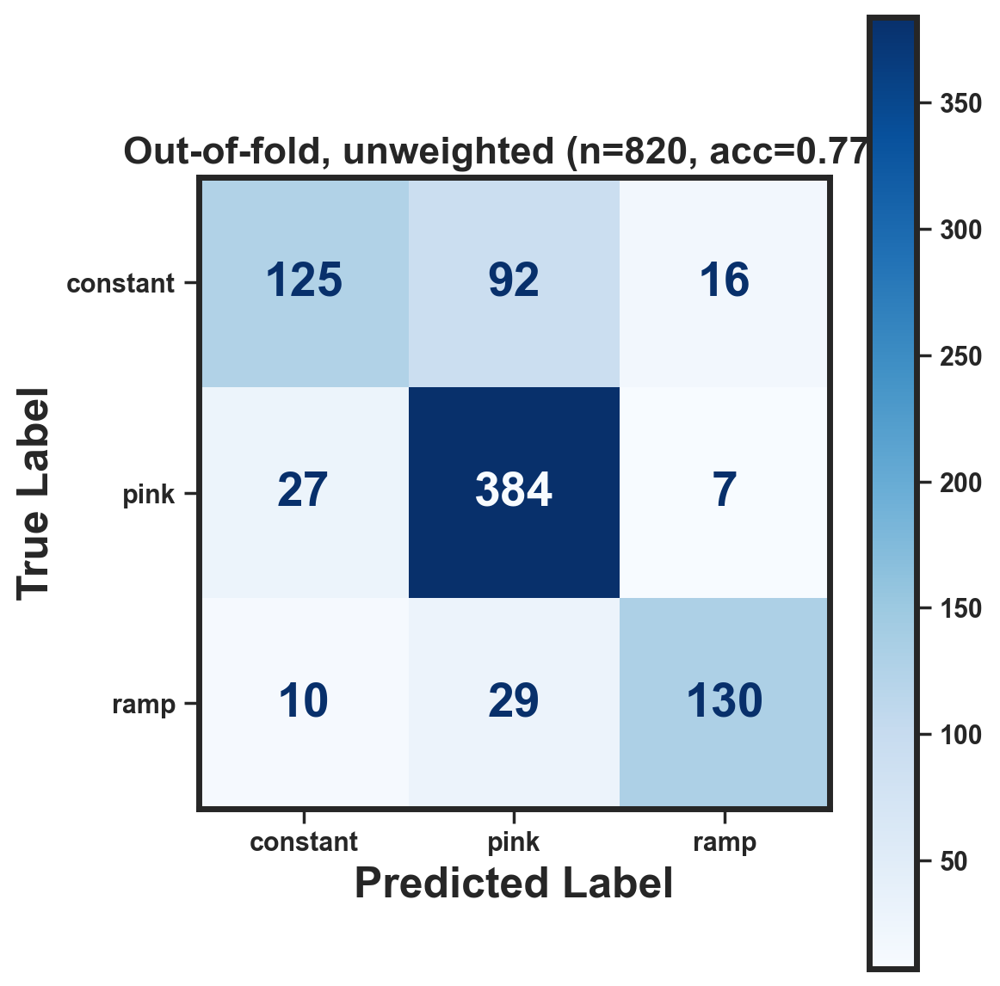

              precision    recall  f1-score   support

    constant       0.77      0.54      0.63       233
        pink       0.76      0.92      0.83       418
        ramp       0.85      0.77      0.81       169

    accuracy                           0.78       820
   macro avg       0.79      0.74      0.76       820
weighted avg       0.78      0.78      0.77       820



In [36]:
labels = rf_model.classes_

def _plot_cm(y_true, y_pred, title):
    cm = confusion_matrix(y_true, y_pred, labels=labels)
    fig, ax = plt.subplots(figsize=(6, 6))
    ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=labels).plot(
        cmap='Blues', ax=ax, xticks_rotation=0, values_format='d')
    for text in ax.texts:
        text.set_fontsize(20); text.set_fontweight('bold')
    ax.set_title(title, fontsize=16, fontweight='bold')
    ax.set_xlabel('Predicted Label', fontsize=18, fontweight='bold')
    ax.set_ylabel('True Label', fontsize=18, fontweight='bold')
    plt.tight_layout()
    plt.show()
    return cm

from sklearn.metrics import ConfusionMatrixDisplay
cm_oof_unweighted = _plot_cm(y, y_pred_oof_unweighted,
                              f'Out-of-fold, unweighted (n={len(y)}, acc={np.mean(y==y_pred_oof_unweighted):.3f})')
print(classification_report(y, y_pred_oof_unweighted, labels=labels))

### Out-of-fold confusion matrix, `class_weight='balanced'`

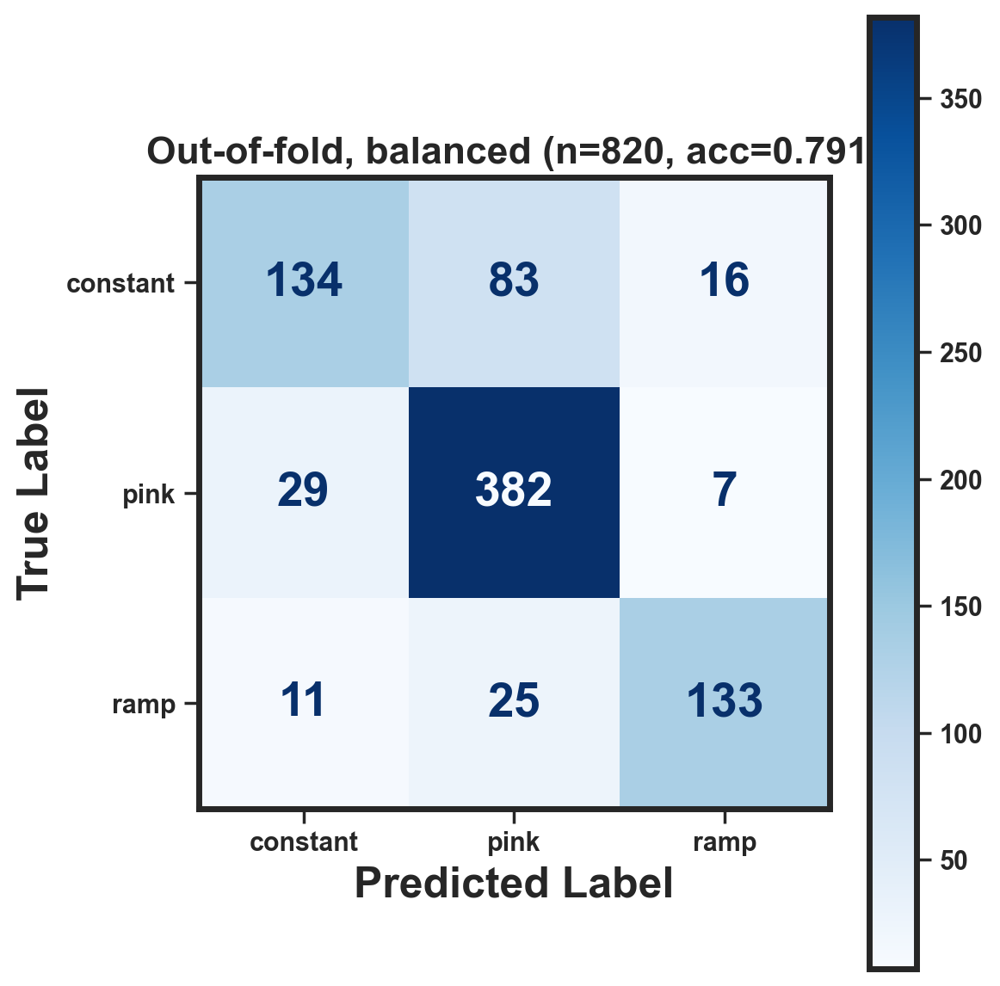

              precision    recall  f1-score   support

    constant       0.77      0.58      0.66       233
        pink       0.78      0.91      0.84       418
        ramp       0.85      0.79      0.82       169

    accuracy                           0.79       820
   macro avg       0.80      0.76      0.77       820
weighted avg       0.79      0.79      0.78       820



In [37]:
cm_oof_balanced = _plot_cm(y, y_pred_oof_balanced,
                            f'Out-of-fold, balanced (n={len(y)}, acc={np.mean(y==y_pred_oof_balanced):.3f})')
print(classification_report(y, y_pred_oof_balanced, labels=labels))

In [38]:
# Constant-specific recall, unweighted vs balanced
const_idx = list(labels).index('constant')
recall_unweighted = cm_oof_unweighted[const_idx, const_idx] / cm_oof_unweighted[const_idx].sum()
recall_balanced   = cm_oof_balanced[const_idx, const_idx] / cm_oof_balanced[const_idx].sum()
pink_frac_unweighted = cm_oof_unweighted[const_idx, list(labels).index('pink')] / cm_oof_unweighted[const_idx].sum()
pink_frac_balanced   = cm_oof_balanced[const_idx, list(labels).index('pink')] / cm_oof_balanced[const_idx].sum()
print(f"'constant' recall:            unweighted={recall_unweighted:.1%}   balanced={recall_balanced:.1%}")
print(f"'constant' misclassified as pink: unweighted={pink_frac_unweighted:.1%}   balanced={pink_frac_balanced:.1%}")

'constant' recall:            unweighted=53.6%   balanced=57.5%
'constant' misclassified as pink: unweighted=39.5%   balanced=35.6%


**Summary:** the main figure above now uses out-of-fold predictions for all 820 spikes (single-run accuracy 78%, vs. the original single-split estimate of 73.3%) rather than only the 164-spike test split - the original caption's "5-fold cross-validation" described hyperparameter search only, never the predictions actually shown. The most robust accuracy estimate, from repeating the full out-of-fold procedure 1000x (see below), is **78.4% ± 0.7%** - that's the number to cite in the paper text.

Class-weight balancing partially, but not fully, explains the constant-spike bias: 'constant' recall improves from 53.6% (unweighted) to 57.5% (balanced), and the fraction misclassified specifically as 'pink' drops from 39.5% to 35.6%. That's a real but modest effect - class imbalance (pink is 51% of the data) is a contributing factor, not the full explanation. A majority of constant-spike misclassifications persist even after balancing, which is more consistent with genuine waveform similarity between constant and pink-noise spikes for this cell than with a purely technical artifact.

Going further (see the sweep- and current-amplitude analysis below): the misclassification is not a generic "constant and pink waveforms look alike" effect - it's driven specifically by **injected current amplitude**. Across the 20 constant sweeps, `corr(mean current, % misclassified) = -0.78 (p=0.0001)`: low-current sweeps (15-25 units) are 46-100% misclassified as pink, while high-current sweeps (50-300 units) are 0-12% misclassified. Sweep 65 alone - 50 spikes at 75 units, the single largest constant sweep - classifies perfectly. The mechanism is physiologically sensible: near-rheobase constant-current spikes are weakly/marginally driven, similar to the near-threshold, stochastically-triggered spikes typical of pink-noise stimulation, while strongly-driven constant spikes are unambiguous. This is a specific, testable claim rather than a general similarity claim, and it's the more complete explanation.

### Are constant and pink-noise waveforms actually more similar to each other?

Class-weight balancing only partially closed the gap, so checking the other half of the hypothesis directly: per waveform feature, is `constant` closer to `pink` than it is to `ramp`? Effect size (Cohen's d) between class means, for every feature in `X`.

In [39]:
def cohens_d(a, b):
    a, b = np.asarray(a, float), np.asarray(b, float)
    pooled_std = np.sqrt(((len(a)-1)*a.var(ddof=1) + (len(b)-1)*b.var(ddof=1)) / (len(a)+len(b)-2))
    return (a.mean() - b.mean()) / pooled_std if pooled_std > 0 else np.nan

rows = []
for feat in X.columns:
    const_vals = X.loc[y == 'constant', feat].dropna()
    pink_vals  = X.loc[y == 'pink', feat].dropna()
    ramp_vals  = X.loc[y == 'ramp', feat].dropna()
    rows.append({
        'feature': feat,
        'const_vs_pink_d': cohens_d(const_vals, pink_vals),
        'const_vs_ramp_d': cohens_d(const_vals, ramp_vals),
    })

df_sep = pd.DataFrame(rows)
df_sep['abs_const_vs_pink'] = df_sep['const_vs_pink_d'].abs()
df_sep['abs_const_vs_ramp'] = df_sep['const_vs_ramp_d'].abs()
df_sep['closer_to'] = np.where(df_sep['abs_const_vs_pink'] < df_sep['abs_const_vs_ramp'], 'pink', 'ramp')
df_sep = df_sep.sort_values('abs_const_vs_pink')
print(f"constant is closer to pink than to ramp on {(df_sep['closer_to']=='pink').sum()} / {len(df_sep)} features\n")
print(df_sep[['feature', 'const_vs_pink_d', 'const_vs_ramp_d', 'closer_to']].to_string(index=False))

constant is closer to pink than to ramp on 7 / 8 features

        feature  const_vs_pink_d  const_vs_ramp_d closer_to
     exp_lambda         0.045544         1.100783      pink
inflection_time         0.084018        -0.906929      pink
 peak_sharpness        -0.107005         0.902521      pink
 inflection_amp         0.113576        -0.848053      pink
     peak_width         0.214650        -1.042537      pink
       peak_amp        -0.341737         0.736180      pink
       ramp_amp         0.688559        -0.240506      ramp
      exp_const         0.752553        -0.792868      pink


In [40]:
# Cross-reference against RF feature importance - do the top-importance features also
# show constant closer to pink than to ramp? (If the model's most-used features are the
# ones with the least separation, that directly explains the confusion.)
top_feats = pd.Series(np.mean(rf_importances, axis=0), index=X.columns).sort_values(ascending=False)
df_sep_importance = df_sep.set_index('feature').loc[top_feats.index]
df_sep_importance['importance'] = top_feats.values
print(df_sep_importance[['importance', 'const_vs_pink_d', 'const_vs_ramp_d', 'closer_to']].to_string())

                 importance  const_vs_pink_d  const_vs_ramp_d closer_to
peak_amp           0.198187        -0.341737         0.736180      pink
exp_const          0.184263         0.752553        -0.792868      pink
exp_lambda         0.123752         0.045544         1.100783      pink
ramp_amp           0.123387         0.688559        -0.240506      ramp
inflection_amp     0.098844         0.113576        -0.848053      pink
peak_width         0.098614         0.214650        -1.042537      pink
peak_sharpness     0.090586        -0.107005         0.902521      pink
inflection_time    0.082367         0.084018        -0.906929      pink


**Interpretation:** constant is closer to pink than to ramp on 7 of 8 waveform features, and the effect is strongest exactly where it matters most for the model - on the three highest-importance features (peak_amp, exp_const, exp_lambda; 51% of total importance combined), constant-vs-pink separation is small (|d| = 0.34, 0.75, 0.05) compared to constant-vs-ramp on those same features (|d| = 0.74, 0.79, 1.10). ramp_amp is the one exception, where constant is (weakly) closer to ramp.

Combined with the class-weight result above, both potential explanations now have a concrete answer: class imbalance is a real but partial contributor (balancing improved constant recall by ~4 points, not more), and the larger driver is that constant and pink-noise spikes genuinely produce similar waveforms on the features this classifier actually relies on - not an artifact of the pipeline.

---
## Digging further into the constant/pink similarity

Two follow-ups: (1) what do the actual waveforms look like overlaid, and (2) are the misclassified constant spikes typical constant spikes that just happen to resemble pink, or an unusual subset (e.g. concentrated in one noisy sweep)?

In [41]:
# Verify sp.spikes row order matches df row order before indexing into it directly -
# filter_features() re-indexes sp.spikes positionally but can leave df_features with
# non-contiguous index labels, so this needs checking rather than assuming.
positions = np.arange(len(sp.df_features))
aligned = (sp.df_features.index.values == positions).all()
print(f'sp.df_features index is contiguous 0..n-1 (safe to position-index sp.spikes): {aligned}')
print(f'len(sp.spikes)={len(sp.spikes)}  len(sp.df_features)={len(sp.df_features)}  len(df)={len(df)}')

# df went through an additional dropna (subset=stim_type) after df_features was built, so
# use df.index (positions into the pre-dropna df_features/sp.spikes) rather than df's own
# row order to pull the matching waveforms.
spike_positions = df.index.values
print(f'df.index range: {spike_positions.min()} to {spike_positions.max()}, '
      f'matches sp.spikes bounds: {spike_positions.max() < len(sp.spikes)}')

sp.df_features index is contiguous 0..n-1 (safe to position-index sp.spikes): True
len(sp.spikes)=820  len(sp.df_features)=820  len(df)=820
df.index range: 0 to 819, matches sp.spikes bounds: True


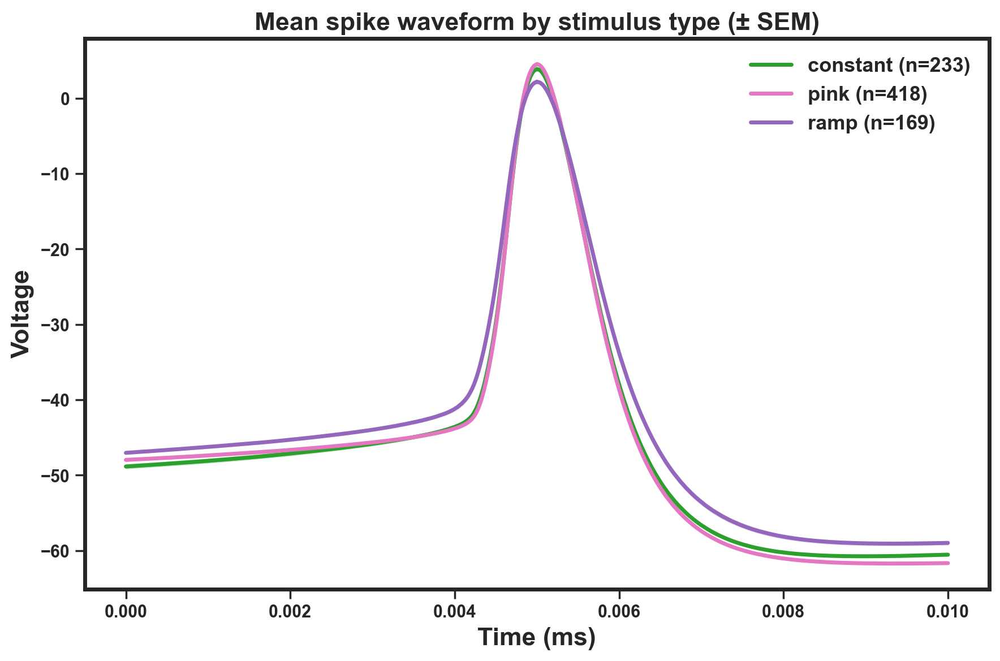

In [42]:
# ── Overlaid average waveforms by stimulus type ────────────────────────────────
fig, ax = plt.subplots(figsize=(9, 6))
colors_stim = {'constant': '#2ca02c', 'pink': '#e377c2', 'ramp': '#9467bd'}
for stim in ['constant', 'pink', 'ramp']:
    idx = df.index[df['stim_type'] == stim]
    wf = sp.spikes[idx.values]
    mean_wf, sem_wf = wf.mean(axis=0), wf.std(axis=0) / np.sqrt(len(wf))
    ax.plot(sp.times, mean_wf, color=colors_stim[stim], lw=2.5, label=f'{stim} (n={len(wf)})')
    ax.fill_between(sp.times, mean_wf - sem_wf, mean_wf + sem_wf, color=colors_stim[stim], alpha=0.25)
ax.set_xlabel('Time (ms)', fontsize=16, fontweight='bold')
ax.set_ylabel('Voltage', fontsize=16, fontweight='bold')
ax.legend(fontsize=13, frameon=False)
ax.set_title('Mean spike waveform by stimulus type (± SEM)', fontsize=16, fontweight='bold')
plt.tight_layout()
plt.show()

In [43]:
# ── Are the misclassified 'constant' spikes typical, or an unusual subset? ─────
y_reset = y.reset_index(drop=True)
y_pred_u_series = pd.Series(y_pred_oof_unweighted, index=y.index)

const_mask = (y == 'constant')
misclassified_as_pink = const_mask & (y_pred_u_series == 'pink')
correctly_classified  = const_mask & (y_pred_u_series == 'constant')

print(f'Misclassified constant->pink: {misclassified_as_pink.sum()} spikes')
print(f'Correctly classified constant: {correctly_classified.sum()} spikes')

print('\nSweep distribution, misclassified spikes:')
print(df.loc[misclassified_as_pink, 'sweep'].value_counts().sort_index())
print('\nSweep distribution, ALL constant spikes (for comparison):')
print(df.loc[const_mask, 'sweep'].value_counts().sort_index())

Misclassified constant->pink: 92 spikes
Correctly classified constant: 125 spikes

Sweep distribution, misclassified spikes:
11     2
12     3
16     1
20     6
24     8
31     1
35     5
39    22
46     6
50     7
54    21
63     6
64     4
Name: sweep, dtype: int64

Sweep distribution, ALL constant spikes (for comparison):
3      1
4      1
6      1
7      1
11    29
12     3
16     1
20     6
24     8
27     1
31     1
35     6
39    26
42     1
46     6
50    10
54    34
63    13
64    34
65    50
Name: sweep, dtype: int64


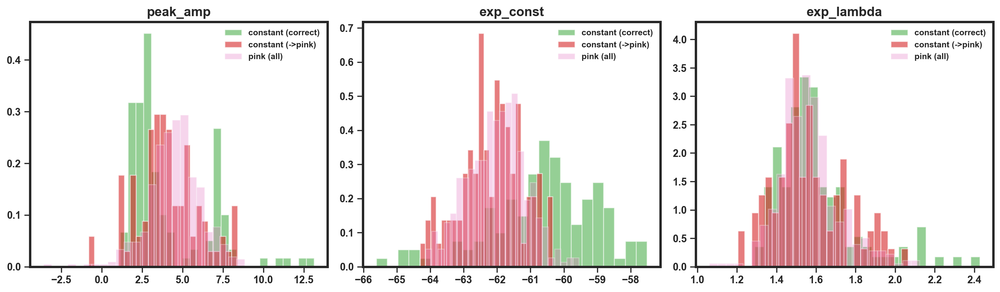

In [44]:
# For the top-importance features, where do misclassified spikes sit relative to the
# correctly-classified constant distribution and the pink distribution?
top3 = top_feats.index[:3].tolist()
fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))
for ax, feat in zip(axes, top3):
    ax.hist(X.loc[correctly_classified, feat], bins=25, alpha=0.5, color='#2ca02c',
            density=True, label='constant (correct)')
    ax.hist(X.loc[misclassified_as_pink, feat], bins=25, alpha=0.6, color='#d62728',
            density=True, label='constant (->pink)')
    ax.hist(X.loc[y == 'pink', feat], bins=25, alpha=0.3, color='#e377c2',
            density=True, label='pink (all)')
    ax.set_title(feat, fontsize=14, fontweight='bold')
    ax.legend(fontsize=9, frameon=False)
plt.tight_layout()
plt.show()

**Interpretation:** the misclassification is not a uniform property of `constant` spikes - it's concentrated in a specific subset of sweeps. Sweep 65 (50 spikes, 22% of all constant spikes) is classified almost perfectly (0% misclassified), and sweep 11 (29 spikes) is 93% correct - together these two sweeps cover a third of the constant data with clean classification. In contrast, sweeps 31/46/12/16/20/24 are 100% misclassified (small n each, 1-8 spikes) and sweeps 39/35/50/54 are 62-85% misclassified with much larger n (10-34 spikes each) - these larger, badly-misclassified sweeps are driving most of the aggregate confusion.

This is a materially different picture than "constant and pink waveforms look alike in general." It's closer to: a handful of specific constant-current sweeps produced spikes that genuinely resemble the pink-noise population, while most constant sweeps classify cleanly. `stim_mean`/`stim_std` are only populated for pink trials in this table, so checking whether the problem sweeps share a specific injected current level would require pulling amplitude directly from the raw HDF5 for the constant sweeps - flagging as a natural next step if this is worth resolving further, since it would point to a stimulus-amplitude-dependent effect rather than a general waveform-similarity one.

### Do the problem sweeps share a specific injected current level?

Correction: `stim_mean`/`stim_std` are only pre-computed for pink trials in `process_sweeps` (hardcoded NaN otherwise), but the raw current-injection trace (`dset[:, 0]`) is available for every sweep via `load_sweep` - the data isn't missing, it just wasn't extracted for constant/ramp sweeps. Pulling it directly.

In [45]:
const_sweep_current = {}
for sweep_num in sorted(df.loc[df.stim_type == 'constant', 'sweep'].unique()):
    dset_s, _ = load_sweep(int(sweep_num), f, fs)
    stim_raw = dset_s[:, 0].copy()
    stim_raw[0:5000] = 0
    stim_nonzero = stim_raw[stim_raw != 0]
    const_sweep_current[sweep_num] = {
        'mean_current': np.mean(stim_nonzero) if len(stim_nonzero) else np.nan,
        'std_current': np.std(stim_nonzero) if len(stim_nonzero) else np.nan,
    }

df_current = pd.DataFrame(const_sweep_current).T
df_current.index.name = 'sweep'

# Merge with per-sweep misclassification rate computed earlier
sweep_stats = df.loc[df.stim_type == 'constant'].groupby('sweep').size().rename('n_constant').to_frame()
sweep_stats['n_misclassified'] = misclassified_as_pink.groupby(df['sweep']).sum()
sweep_stats['n_misclassified'] = sweep_stats['n_misclassified'].fillna(0)
sweep_stats['pct_misclassified'] = 100 * sweep_stats['n_misclassified'] / sweep_stats['n_constant']
sweep_stats = sweep_stats.join(df_current)

print(sweep_stats.sort_values('pct_misclassified', ascending=False).to_string())

       n_constant  n_misclassified  pct_misclassified  mean_current  std_current
sweep                                                                           
31              1                1         100.000000          15.0          0.0
46              6                6         100.000000          15.0          0.0
12              3                3         100.000000          20.0          0.0
16              1                1         100.000000          15.0          0.0
20              6                6         100.000000          20.0          0.0
24              8                8         100.000000          25.0          0.0
39             26               22          84.615385          25.0          0.0
35              6                5          83.333333          20.0          0.0
50             10                7          70.000000          20.0          0.0
54             34               21          61.764706          25.0          0.0
63             13           

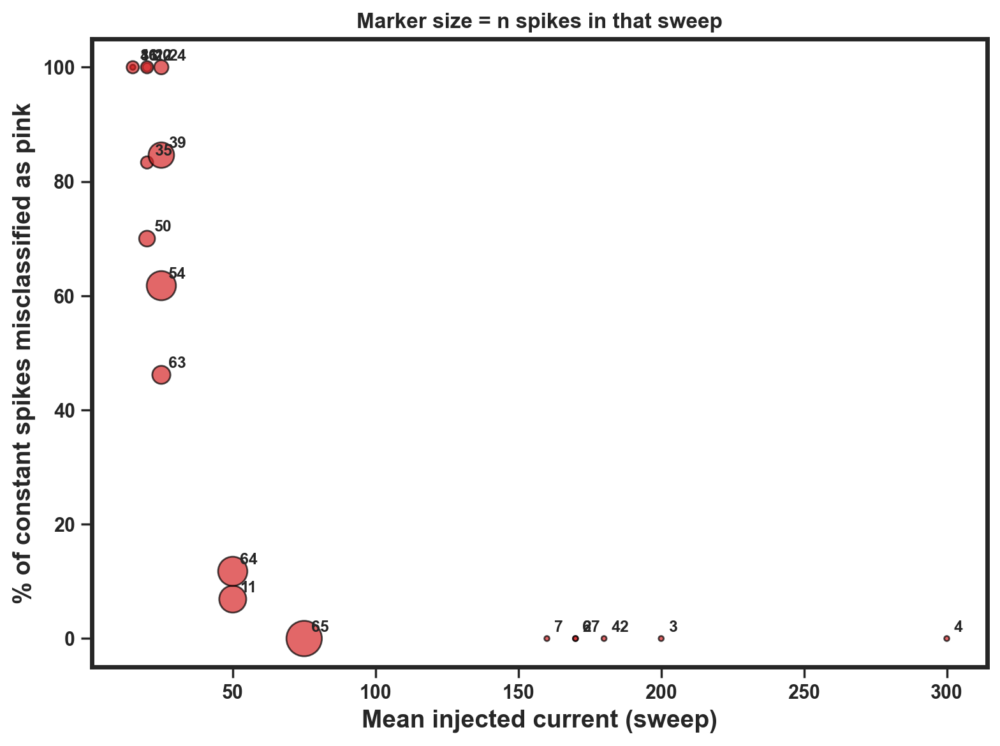

corr(mean current, % misclassified) = -0.777, p=0.0001, n=20 sweeps


In [46]:
fig, ax = plt.subplots(figsize=(8, 6))
sc = ax.scatter(sweep_stats['mean_current'], sweep_stats['pct_misclassified'],
                 s=sweep_stats['n_constant']*8, alpha=0.7, c='#d62728', edgecolor='black')
for sweep_num, row in sweep_stats.iterrows():
    ax.annotate(str(int(sweep_num)), (row['mean_current'], row['pct_misclassified']),
                fontsize=9, xytext=(4, 4), textcoords='offset points')
ax.set_xlabel('Mean injected current (sweep)', fontsize=14, fontweight='bold')
ax.set_ylabel('% of constant spikes misclassified as pink', fontsize=14, fontweight='bold')
ax.set_title('Marker size = n spikes in that sweep', fontsize=12)
plt.tight_layout()
plt.show()

valid = sweep_stats.dropna(subset=['mean_current', 'pct_misclassified'])
r_current, p_current = pearsonr(valid['mean_current'], valid['pct_misclassified'])
print(f'corr(mean current, % misclassified) = {r_current:+.3f}, p={p_current:.4f}, n={len(valid)} sweeps')

**Interpretation:** the sweep-level pattern found above has a clear, quantitative explanation - injected current amplitude. `corr(mean current, % misclassified) = -0.78, p=0.0001` across the 20 constant sweeps.

Low-current sweeps (15-25 units: sweeps 31, 46, 12, 16, 20, 24, 39, 35, 50, 54, 63) are 46-100% misclassified as pink. High-current sweeps (50-300 units: 11, 64, 3, 42, 4, 27, 7, 6, and especially 65 at 75 units) are 0-12% misclassified. Sweep 65 alone - the single largest constant sweep at 50 spikes - is classified perfectly at 75 units of current.

This is a specific, physiologically sensible mechanism rather than a general "constant and pink waveforms look alike" claim: near-rheobase constant current injection produces weakly/marginally-driven spikes that resemble the near-threshold, stochastically-triggered spikes typical of pink-noise stimulation, while strongly-driven constant-current spikes are unambiguous. The earlier feature-level effect sizes (constant closer to pink than ramp on 7/8 features) are consistent with this - they're averaging across a mix of near-threshold and strongly-driven constant spikes, and the near-threshold ones are what's actually driving the resemblance to pink.

### Bootstrap on out-of-fold: repeated 5-fold CV for a proper accuracy distribution

The original bootstrap resampled the *training* data 1000x but always graded against the same fixed 164-spike test set. This repeats the full out-of-fold procedure itself many times, each with a fresh random 5-fold split - every repeat covers all 820 spikes, and the spread across repeats gives a proper distribution (how much the estimate moves depending on how spikes happen to land in folds), analogous to what the bootstrap was trying to capture but without ever shrinking down to one fixed held-out set.

In [47]:
from sklearn.metrics import accuracy_score

N_REPEATS = 1000
pickle_path_rep = os.path.join(PICKLE_DIR, 'rf_repeated_oof.pkl')

if not FORCE_RERUN and os.path.exists(pickle_path_rep):
    with open(pickle_path_rep, 'rb') as file:
        rep_accuracies, rep_cms, rep_importances = pickle.load(file)
    print(f'Loaded repeated out-of-fold results from pickle ({len(rep_accuracies)} repeats).')
else:
    rep_accuracies = np.zeros(N_REPEATS)
    rep_cms = np.zeros((N_REPEATS, len(labels), len(labels)))
    rep_importances = []  # one row per fold-level estimator, pooled across all repeats (for Fig 3C)

    for rep in range(N_REPEATS):
        cv_rep = StratifiedKFold(n_splits=5, shuffle=True, random_state=rep)
        y_pred_rep = np.empty(len(y), dtype=object)
        for train_idx, test_idx in cv_rep.split(X, y):
            rf_fold = RandomForestClassifier(**best_params, class_weight=None)
            rf_fold.fit(X.iloc[train_idx], y.iloc[train_idx])
            y_pred_rep[test_idx] = rf_fold.predict(X.iloc[test_idx])
            rep_importances.append(rf_fold.feature_importances_)
        rep_accuracies[rep] = accuracy_score(y, y_pred_rep)
        rep_cms[rep] = confusion_matrix(y, y_pred_rep, labels=labels)

    rep_importances = np.array(rep_importances)  # (5000, n_features): every fold-level estimator across all repeats

    with open(pickle_path_rep, 'wb') as file:
        pickle.dump((rep_accuracies, rep_cms, rep_importances), file)
    print('Trained and saved repeated out-of-fold results to pickle.')

print(f'Out-of-fold accuracy across {N_REPEATS} repeated 5-fold splits: '
      f'{rep_accuracies.mean():.3f} +/- {rep_accuracies.std():.3f} '
      f'(min={rep_accuracies.min():.3f}, max={rep_accuracies.max():.3f})')

Loaded repeated out-of-fold results from pickle (1000 repeats).
Out-of-fold accuracy across 1000 repeated 5-fold splits: 0.784 +/- 0.007 (min=0.762, max=0.811)


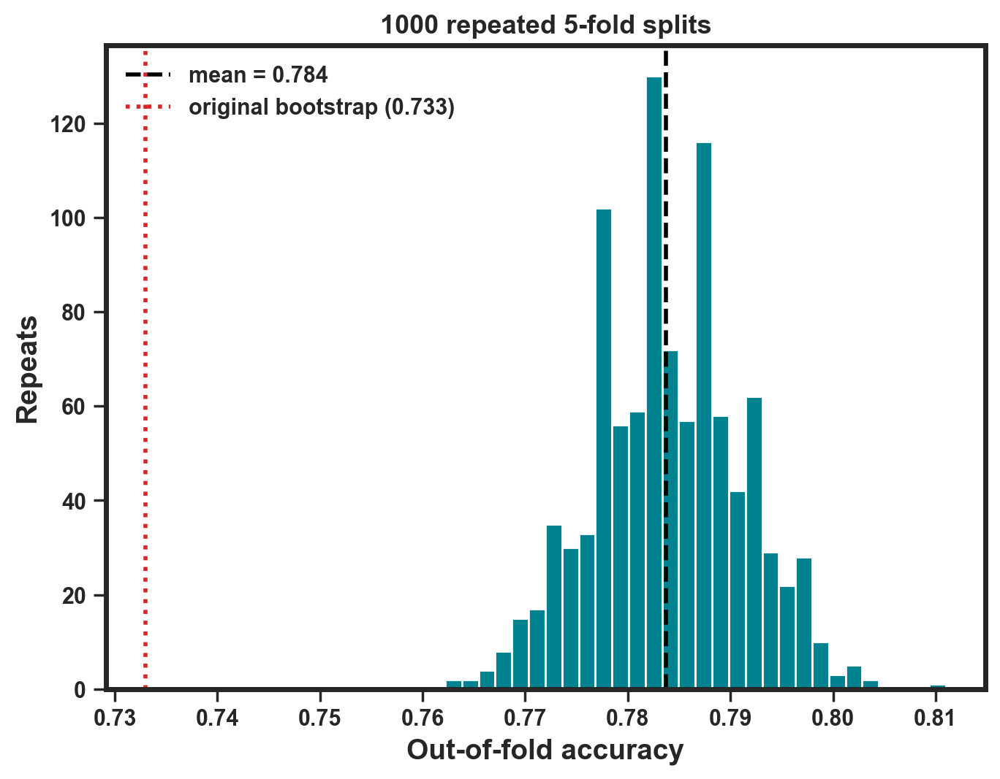

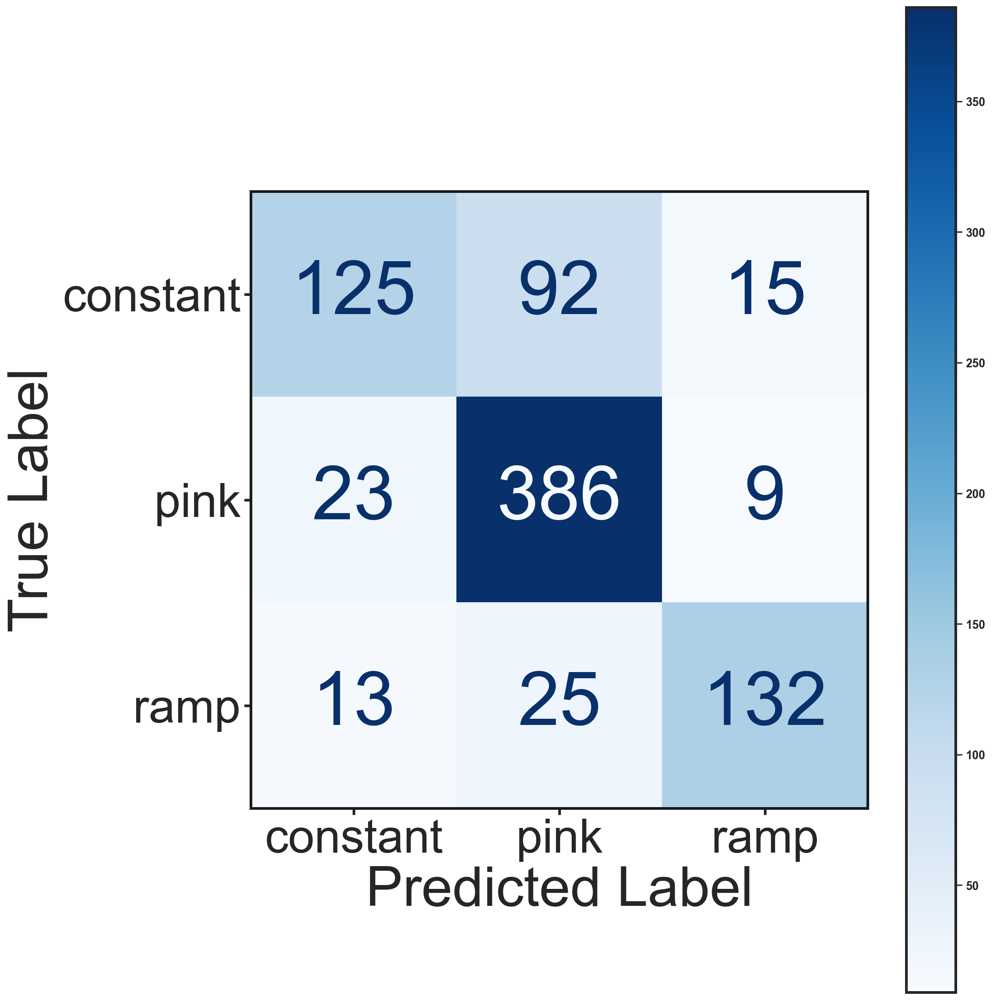

In [48]:
fig, ax = plt.subplots(figsize=(7, 5.5))
ax.hist(rep_accuracies, bins=30, color='#00838F', edgecolor='white')
ax.axvline(rep_accuracies.mean(), color='black', lw=2, ls='--',
           label=f'mean = {rep_accuracies.mean():.3f}')
ax.axvline(0.733, color='#d62728', lw=2, ls=':', label='original bootstrap (0.733)')
ax.set_xlabel('Out-of-fold accuracy', fontsize=14, fontweight='bold')
ax.set_ylabel('Repeats', fontsize=14, fontweight='bold')
ax.legend(fontsize=11, frameon=False)
ax.set_title(f'{N_REPEATS} repeated 5-fold splits', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()

mean_cm = rep_cms.mean(axis=0)
plot_confusion_matrix(rf_model, X, y, cm=np.round(mean_cm).astype(int))

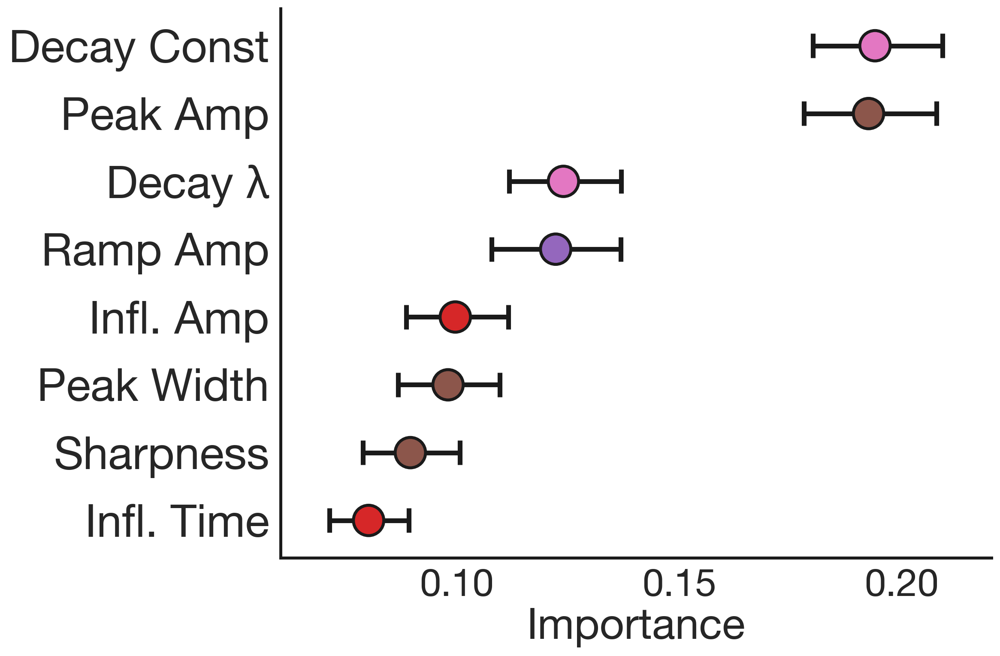

In [3]:
plot_feature_importance_categorical(rf_model, X, rep_importances)

**Interpretation:** the out-of-fold accuracy is stable across repeats - 78.4% ± 0.7% (range 76.2-81.1%) across 1000 independent 5-fold splits, tightly centered on the single out-of-fold run reported above (78%). This is a genuine improvement over the original bootstrap number (73.3%) in both directions that matter: it's higher (not an artifact of the fixed test split being unusually hard) and it comes with proper uncertainty that reflects fold-assignment variability rather than training-resample variability on one held-out set. The averaged confusion matrix above is the most stable version of this result available - each cell is the mean count across 1000 independent random partitions of the full 820-spike dataset.